---

# **Project Details**

**Author**: Sai Gavaskar Sakalam

**Date**: June 3, 2026

**Program**: UT Austin – Post Graduate Program in Artificial Intelligence & Machine Learning

**Project**: Easy Visa

---

# **Problem Statement**

## Context

In the US, an employer who wants to hire a foreign worker needs a labor certification from the Office of Foreign Labor Certification (OFLC). OFLC certifies a case when the employer shows that there are not enough US workers for the job at the prevailing wage.

In FY 2016, OFLC processed about 776,000 employer applications, 9% more than the year before. With more applications every year, reviewing every case by hand is becoming slow.

## Objective

Build a classification model that predicts whether a visa case will be **certified** or **denied**, so that applications can be shortlisted faster. Find the factors that drive approval, and describe the applicant profiles most likely to be certified or denied.

## Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

- case\_id: ID of each visa application
- continent: Information of continent the employee
- education\_of\_employee: Information of education of the employee
- has\_job\_experience: Does the employee has any job experience? Y= Yes; N = No
- requires\_job\_training: Does the employee require any job training? Y = Yes; N = No
- no\_of\_employees: Number of employees in the employer's company
- yr\_of\_estab: Year in which the employer's company was established
- region\_of\_employment: Information of foreign worker's intended region of employment in the US.
- prevailing\_wage: Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
- unit\_of\_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
- full\_time\_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
- case\_status: Flag indicating if the Visa was certified or denied

# **Importing necessary libraries**

In [2]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 xgboost==3.0.5 -q --user

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.9/94.9 MB 8.6 MB/s eta 0:00:00



**Note:** after the install cell finishes, restart the runtime (Colab) or kernel (Jupyter), then run the rest of the notebook from the next cell.

In [3]:
# On Google Colab: mount Drive and point the data path to your Drive folder.
# Library to suppress warnings or deprecation notes
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Library to split data
from sklearn.model_selection import train_test_split

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Libraries for ensemble models
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)

# Libraries for tree-based models
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

# Libraries for model evaluation metrics
from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Library for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# **Loading the dataset**

In [5]:
# On Google Colab: mount Drive and point the data path to your Drive folder.
# Load the EasyVisa dataset from the local data/ folder
easyvisa_df = pd.read_csv('data/EasyVisa.csv')

# Display the first few rows of the DataFrame to confirm successful loading
print(easyvisa_df.head())

  case_id continent education_of_employee has_job_experience  \
0  EZYV01      Asia           High School                  N   
1  EZYV02      Asia              Master's                  Y   
2  EZYV03      Asia            Bachelor's                  N   
3  EZYV04      Asia            Bachelor's                  N   
4  EZYV05    Africa              Master's                  Y   

  requires_job_training  no_of_employees  yr_of_estab region_of_employment  \
0                     N            14513         2007                 West   
1                     N             2412         2002            Northeast   
2                     Y            44444         2008                 West   
3                     N               98         1897                 West   
4                     N             1082         2005                South   

   prevailing_wage unit_of_wage full_time_position case_status  
0         592.2029         Hour                  Y      Denied  
1       83425.65

In [6]:
# Create a deep copy of the original DataFrame to work on, preserving the original.
easyvisa_df_copy = easyvisa_df.copy(deep=True)

# Display the first few rows of the copied DataFrame to confirm
print("First 5 rows of easyvisa_df_copy:")
print(easyvisa_df_copy.head())

First 5 rows of easyvisa_df_copy:
  case_id continent education_of_employee has_job_experience  \
0  EZYV01      Asia           High School                  N   
1  EZYV02      Asia              Master's                  Y   
2  EZYV03      Asia            Bachelor's                  N   
3  EZYV04      Asia            Bachelor's                  N   
4  EZYV05    Africa              Master's                  Y   

  requires_job_training  no_of_employees  yr_of_estab region_of_employment  \
0                     N            14513         2007                 West   
1                     N             2412         2002            Northeast   
2                     Y            44444         2008                 West   
3                     N               98         1897                 West   
4                     N             1082         2005                South   

   prevailing_wage unit_of_wage full_time_position case_status  
0         592.2029         Hour                

# **Overview of the Dataset**

- Observations
- Sanity checks

In [7]:
# Display the concise summary of the copied DataFrame to get data types and non-null counts
print('easyvisa_df_copy Info:')
easyvisa_df_copy.info()

easyvisa_df_copy Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB



In [8]:
# Display the shape of the copied DataFrame (rows, columns)
print('\n--- easyvisa_df_copy Shape ---')
print(f'Rows: {easyvisa_df_copy.shape[0]}, Columns: {easyvisa_df_copy.shape[1]}')


--- easyvisa_df_copy Shape ---
Rows: 25480, Columns: 12



In [9]:
# Display descriptive statistics for numerical columns of the copied DataFrame
print('\n--- Descriptive Statistics for easyvisa_df_copy ---')
display(easyvisa_df_copy.describe().T)


--- Descriptive Statistics for easyvisa_df_copy ---



,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


In [10]:
# Check for duplicate rows in the copied DataFrame
duplicate_rows_copy = easyvisa_df_copy.duplicated().sum()
print(f'\n--- Duplicate Rows Check ---')
print(f'Number of duplicate rows in easyvisa_df_copy: {duplicate_rows_copy}')

if duplicate_rows_copy > 0:
    print('Dropping duplicate rows from easyvisa_df_copy...')
    easyvisa_df_copy.drop_duplicates(inplace=True)
    print(f'New shape of easyvisa_df_copy after dropping duplicates: {easyvisa_df_copy.shape}')
else:
    print('No duplicate rows found.')


--- Duplicate Rows Check ---
Number of duplicate rows in easyvisa_df_copy: 0
No duplicate rows found.



In [11]:
# Check for missing values in the copied DataFrame
print('\n--- Missing Values in easyvisa_df_copy ---')
missing_values_copy = easyvisa_df_copy.isnull().sum()
missing_percentage_copy = 100 * easyvisa_df_copy.isnull().sum() / len(easyvisa_df_copy)
missing_df_copy = pd.DataFrame({'Missing Count': missing_values_copy, 'Missing Percentage (%)': missing_percentage_copy})
display(missing_df_copy[missing_df_copy['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))


--- Missing Values in easyvisa_df_copy ---



,Missing Count,Missing Percentage (%)


# **Exploratory Data Analysis (EDA)**

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions explored in the EDA**

1. What is the distribution of visa case statuses (certified vs. denied)?
2. How does the education level of employees impact visa approval rates?
3. Is there a significant difference in visa approval rates between employees with and without prior job experience?
4. How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?
5. Do certain regions in the US have higher visa approval rates compared to others?
6. How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?
7. Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?

### 1. Distribution of Visa Case Statuses

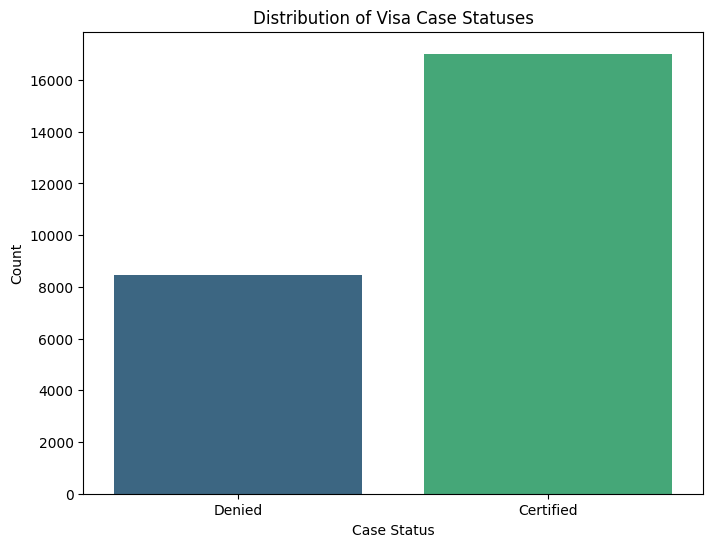

In [13]:
# Get the value counts of 'case_status'
case_status_counts = easyvisa_df_copy['case_status'].value_counts()

# Plotting the distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=easyvisa_df_copy, x='case_status', palette='viridis')
plt.title('Distribution of Visa Case Statuses')
plt.xlabel('Case Status')
plt.ylabel('Count')
plt.show()

# Convert 'case_status' to numerical for correlation and later modeling
easyvisa_df_copy['case_status_encoded'] = easyvisa_df_copy['case_status'].map({'Denied': 0, 'Certified': 1})

#### Observations on Case Status Distribution:

- **Distribution:**
  - Certified: 17018 cases
  - Denied: 8462 cases
- The majority of visa applications are Certified (66.79%).
- This indicates a class imbalance, which might need to be addressed during model building.

### 2. Education Level Impact on Visa Approval Rates

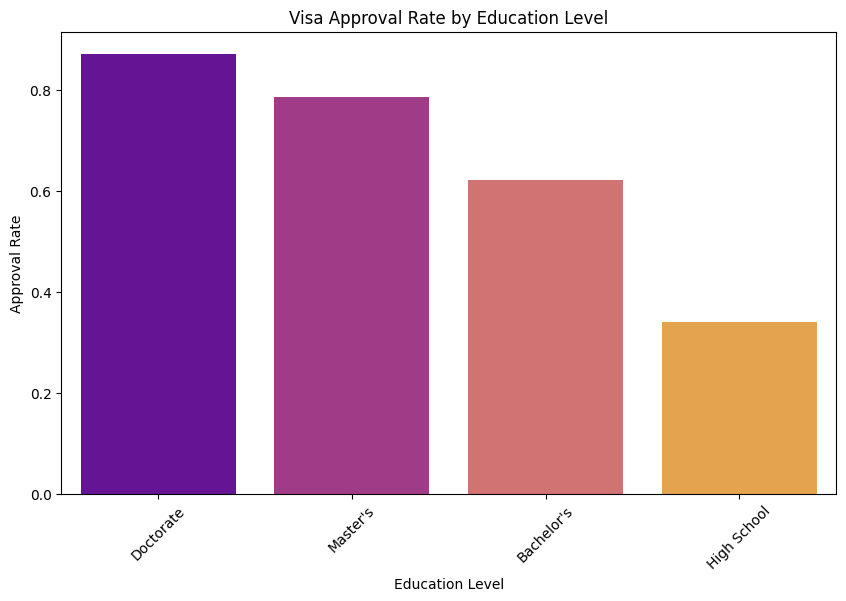

In [14]:
# Calculate approval rates per education level
education_approval = easyvisa_df_copy.groupby('education_of_employee')['case_status_encoded'].mean().sort_values(ascending=False)

# Plotting the impact of education on approval rates
plt.figure(figsize=(10, 6))
sns.barplot(x=education_approval.index, y=education_approval.values, palette='plasma')
plt.title('Visa Approval Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Approval Rate')
plt.xticks(rotation=45)
plt.show()

#### Observations on Education Level and Visa Approval:

- **Approval Rates by Education Level:**
  - Doctorate: 87.23%
  - Master's: 78.63%
  - Bachelor's: 62.21%
  - High School: 34.04%
- Doctorate has the highest approval rate (87.23%).
- High School has the lowest approval rate (34.04%).
- Higher education levels generally correlate with higher visa approval rates.

### 3. Job Experience Impact on Visa Approval Rates

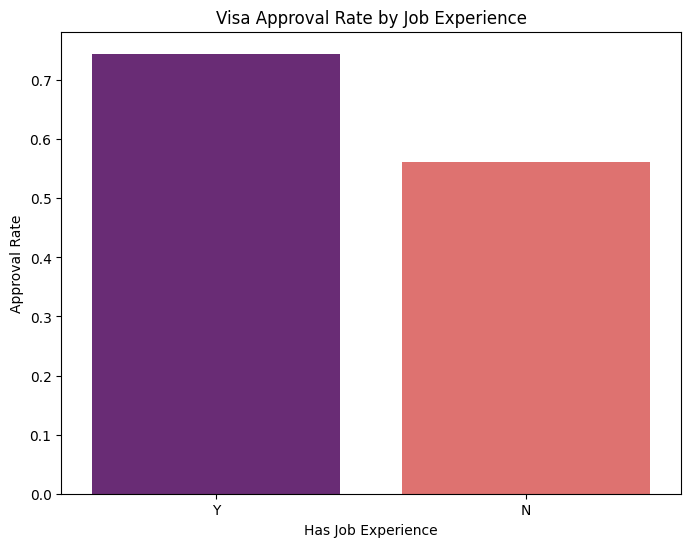

In [15]:
# Calculate approval rates for job experience categories
experience_approval = easyvisa_df_copy.groupby('has_job_experience')['case_status_encoded'].mean().sort_values(ascending=False)

# Plotting the impact of job experience on approval rates
plt.figure(figsize=(8, 6))
sns.barplot(x=experience_approval.index, y=experience_approval.values, palette='magma')
plt.title('Visa Approval Rate by Job Experience')
plt.xlabel('Has Job Experience')
plt.ylabel('Approval Rate')
plt.show()

#### Observations on Job Experience and Visa Approval:

- **Approval Rates by Job Experience:**
  - Has Job Experience (Y): 74.48%
  - No Job Experience (N): 56.13%
- Employees with job experience ('Y') have a significantly higher approval rate (74.48%) than those without ('N', 56.13%).

### 4. Prevailing Wage and Visa Approval

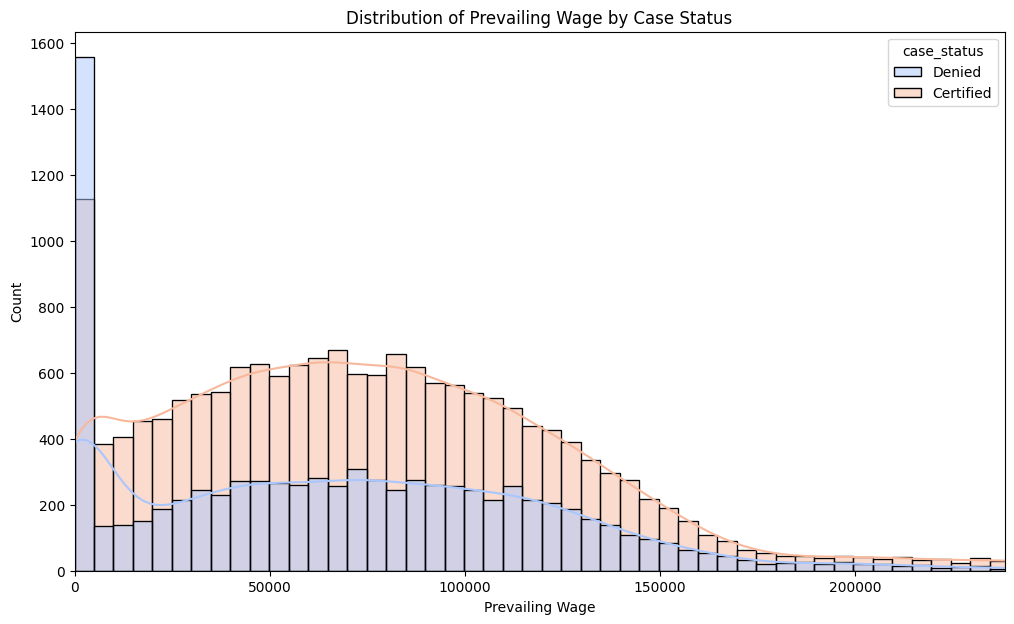

In [16]:
# Analyze the distribution of prevailing wage for certified vs. denied cases
plt.figure(figsize=(12, 7))
sns.histplot(data=easyvisa_df_copy, x='prevailing_wage', hue='case_status', kde=True, palette='coolwarm')
plt.title('Distribution of Prevailing Wage by Case Status')
plt.xlabel('Prevailing Wage')
plt.ylabel('Count')
plt.xlim(0, easyvisa_df_copy['prevailing_wage'].quantile(0.99)) # Limit x-axis for better visualization due to outliers
plt.show()

# Compare mean/median prevailing wage
prevailing_wage_stats = easyvisa_df_copy.groupby('case_status')['prevailing_wage'].agg(['mean', 'median', 'std'])

#### Observations on Prevailing Wage and Visa Approval:

- **Prevailing Wage Statistics by Case Status:**
  - Certified: Mean = 77293.62, Median = 72486.27, Std = 52042.72
  - Denied: Mean = 68748.68, Median = 65431.46, Std = 53890.17
- The distribution of prevailing wage for certified cases appears to be slightly higher and wider than for denied cases.
- The mean prevailing wage for Certified cases is 77293.62, while for Denied cases it is 68748.68.
- This suggests that higher prevailing wages might contribute to a higher chance of visa approval.

### 5. Regional Differences in Visa Approval Rates

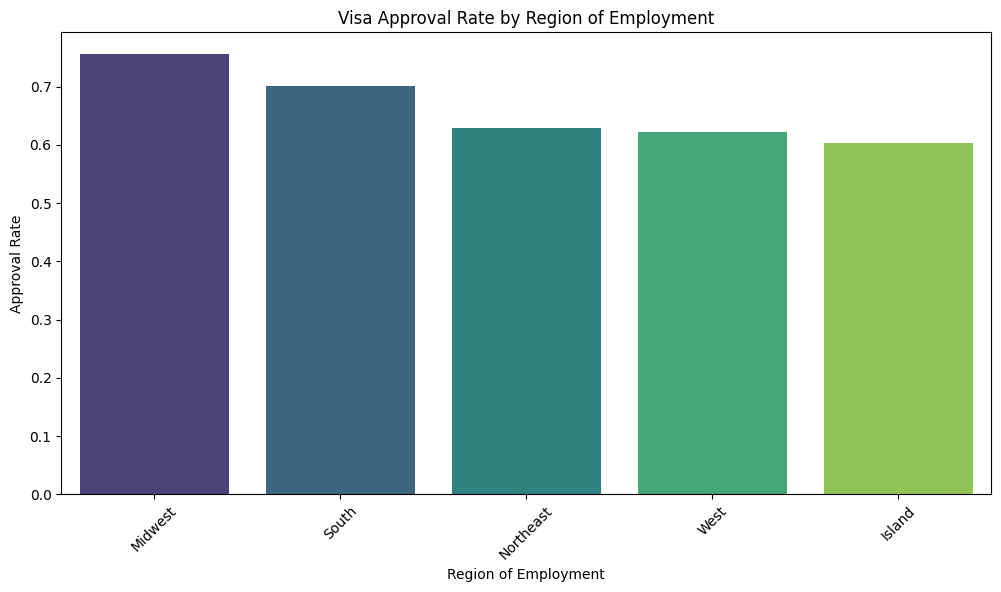

In [17]:
# Calculate approval rates per region of employment
region_approval = easyvisa_df_copy.groupby('region_of_employment')['case_status_encoded'].mean().sort_values(ascending=False)

# Plotting the impact of region on approval rates
plt.figure(figsize=(12, 6))
sns.barplot(x=region_approval.index, y=region_approval.values, palette='viridis')
plt.title('Visa Approval Rate by Region of Employment')
plt.xlabel('Region of Employment')
plt.ylabel('Approval Rate')
plt.xticks(rotation=45)
plt.show()

#### Observations on Region of Employment and Visa Approval:

- **Approval Rates by Region of Employment:**
  - Midwest: 75.53%
  - South: 70.02%
  - Northeast: 62.90%
  - West: 62.25%
  - Island: 60.27%
- The 'Midwest' region has the highest approval rate (75.53%).
- The 'Island' region has the lowest approval rate (60.27%).
- There are noticeable differences in approval rates across regions, indicating regional factors might play a role.

### 6. Number of Employees and Visa Approval

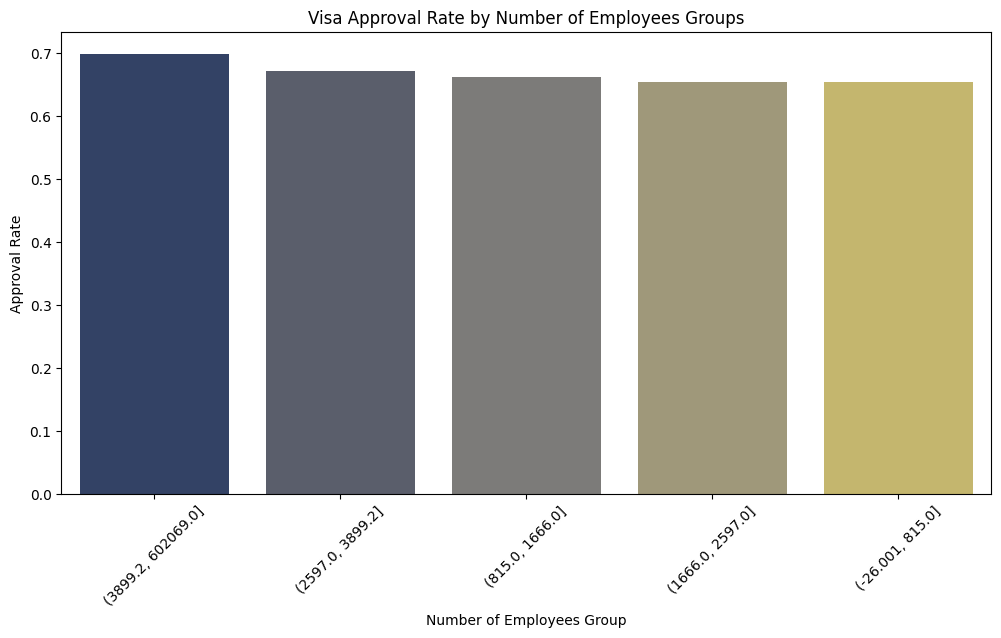

In [18]:
# Create bins for no_of_employees for better visualization if the range is too wide
# For simplicity, let's look at the correlation and potential segmentation.
# Due to large range, let's categorize 'no_of_employees' into bins
easyvisa_df_copy['employee_count_group'] = pd.qcut(easyvisa_df_copy['no_of_employees'], q=5, duplicates='drop')

employee_group_approval = easyvisa_df_copy.groupby('employee_count_group')['case_status_encoded'].mean().sort_values(ascending=False)

# Plotting the impact of number of employees on approval rates
plt.figure(figsize=(12, 6))
sns.barplot(x=employee_group_approval.index.astype(str), y=employee_group_approval.values, palette='cividis')
plt.title('Visa Approval Rate by Number of Employees Groups')
plt.xlabel('Number of Employees Group')
plt.ylabel('Approval Rate')
plt.xticks(rotation=45)
plt.show()

#### Observations on Number of Employees and Visa Approval:

- **Approval Rates by Number of Employees (Grouped):**
  - (3899.2, 602069.0]: 69.86%
  - (2597.0, 3899.2]: 67.11%
  - (815.0, 1666.0]: 66.22%
  - (1666.0, 2597.0]: 65.43%
  - (-26.001, 815.0]: 65.33%
- Generally, larger companies (higher number of employees) tend to have higher visa approval rates.
- This could be due to more established processes or resources in larger organizations.

### 7. Continents of Employees and Visa Approval Rates

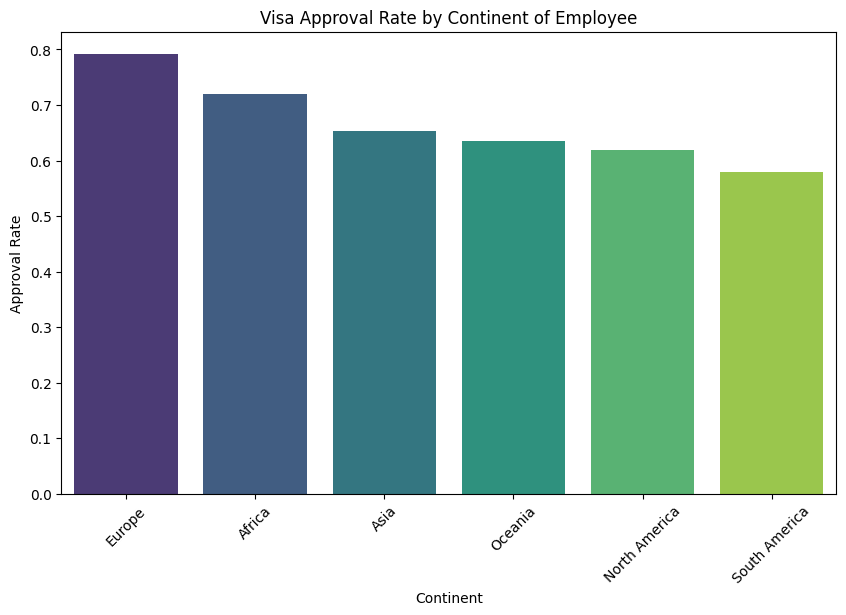

In [19]:
# Calculate approval rates per continent
continent_approval = easyvisa_df_copy.groupby('continent')['case_status_encoded'].mean().sort_values(ascending=False)

# Plotting the impact of continent on approval rates
plt.figure(figsize=(10, 6))
sns.barplot(x=continent_approval.index, y=continent_approval.values, palette='viridis')
plt.title('Visa Approval Rate by Continent of Employee')
plt.xlabel('Continent')
plt.ylabel('Approval Rate')
plt.xticks(rotation=45)
plt.show()

#### Observations on Continent and Visa Approval:

- **Approval Rates by Continent:**
  - Europe: 79.23%
  - Africa: 72.05%
  - Asia: 65.31%
  - Oceania: 63.54%
  - North America: 61.88%
  - South America: 57.86%
- Europe has the highest visa approval rate (79.23%).
- South America has the lowest visa approval rate (57.86%).
- Significant variations in approval rates are observed across different continents.

### 8. Job Training Requirement and Visa Approval Rates

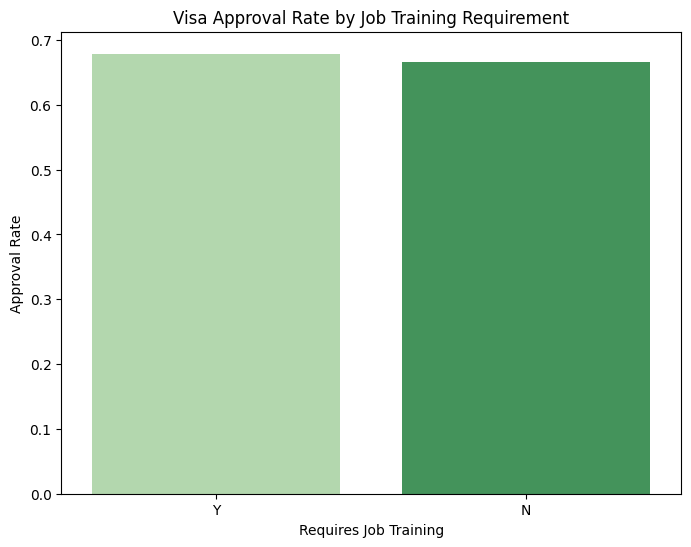

In [20]:
# Calculate approval rates for job training requirement
training_approval = easyvisa_df_copy.groupby('requires_job_training')['case_status_encoded'].mean().sort_values(ascending=False)

# Plotting the impact of job training on approval rates
plt.figure(figsize=(8, 6))
sns.barplot(x=training_approval.index, y=training_approval.values, palette='Greens')
plt.title('Visa Approval Rate by Job Training Requirement')
plt.xlabel('Requires Job Training')
plt.ylabel('Approval Rate')
plt.show()

#### Observations on Job Training Requirement and Visa Approval:

- **Approval Rates by Job Training Requirement:**
  - Y: 67.88%
  - N: 66.65%
- Employees who **do** require job training ('Y') have a slightly higher approval rate (67.88%) than those who do not ('N', 66.65%).
- This could suggest that applicants who are ready to work immediately without additional training are preferred, or that jobs requiring training are less likely to be certified.

### 9. Year of Establishment and Visa Approval Rates

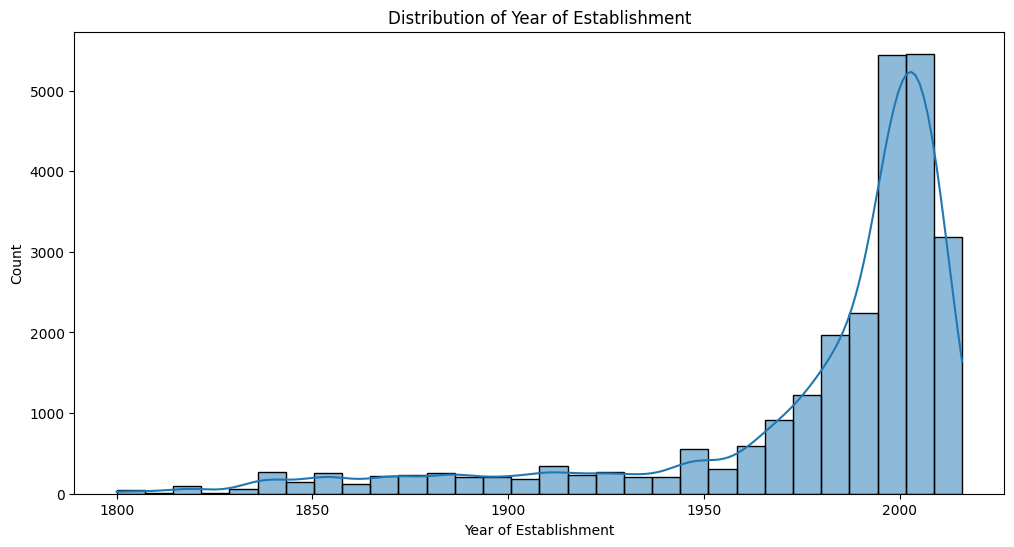

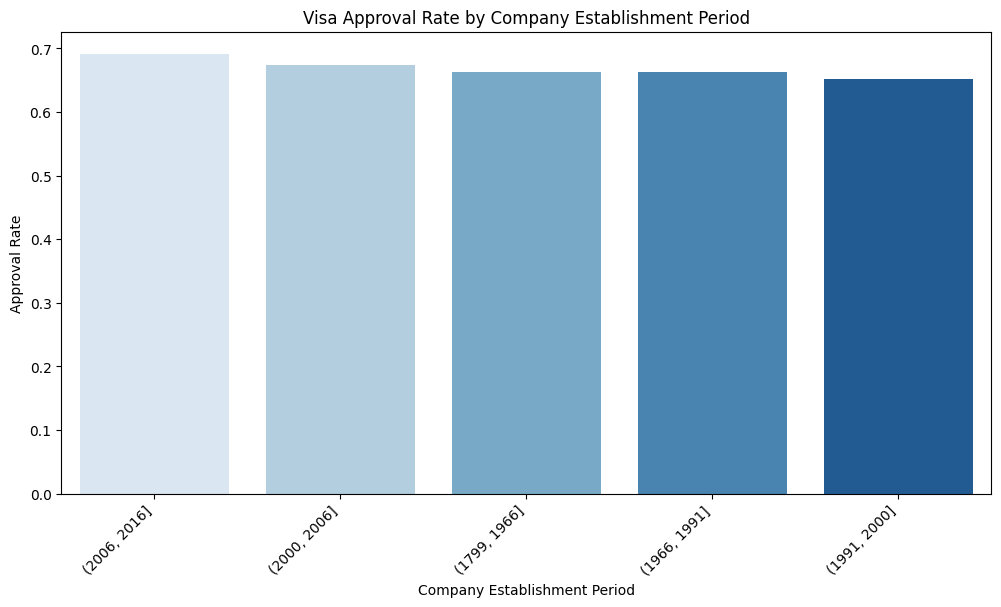

In [21]:
# To analyze year of establishment, let's group `yr_of_estab` into bins or analyze its distribution relative to approval.
# First, let's see the distribution of `yr_of_estab`.
plt.figure(figsize=(12, 6))
sns.histplot(easyvisa_df_copy['yr_of_estab'], bins=30, kde=True)
plt.title('Distribution of Year of Establishment')
plt.xlabel('Year of Establishment')
plt.ylabel('Count')
plt.show()

# Let's categorize the 'yr_of_estab' into broader historical periods or quartiles for approval rates
# Using qcut to get quartiles for a more balanced distribution
easyvisa_df_copy['establishment_period'] = pd.qcut(easyvisa_df_copy['yr_of_estab'], q=5, duplicates='drop')

estab_approval = easyvisa_df_copy.groupby('establishment_period')['case_status_encoded'].mean().sort_values(ascending=False)

# Format the index of estab_approval for better display, removing the .0 from bin edges
formatted_labels = [f"({int(interval.left)}, {int(interval.right)}]" for interval in estab_approval.index]

# Plotting the impact of establishment period on approval rates
plt.figure(figsize=(12, 6))
sns.barplot(x=formatted_labels, y=estab_approval.values, palette='Blues')
plt.title('Visa Approval Rate by Company Establishment Period')
plt.xlabel('Company Establishment Period')
plt.ylabel('Approval Rate')
plt.xticks(rotation=45, ha='right')
plt.show()

#### Observations on Year of Establishment and Visa Approval:

- **Approval Rates by Company Establishment Period:**
  - (2006, 2016): 69.17%
  - (2000, 2006): 67.34%
  - (1799, 1966): 66.29%
  - (1966, 1991): 66.27%
  - (1991, 2000): 65.18%
- Companies established more recently (e.g., in the 2000s) appear to have slightly higher visa approval rates compared to very old companies.
- This might be due to various factors such as modern industry focus, growth, or compliance practices.

### 10. Full-Time Position Requirement and Visa Approval Rates

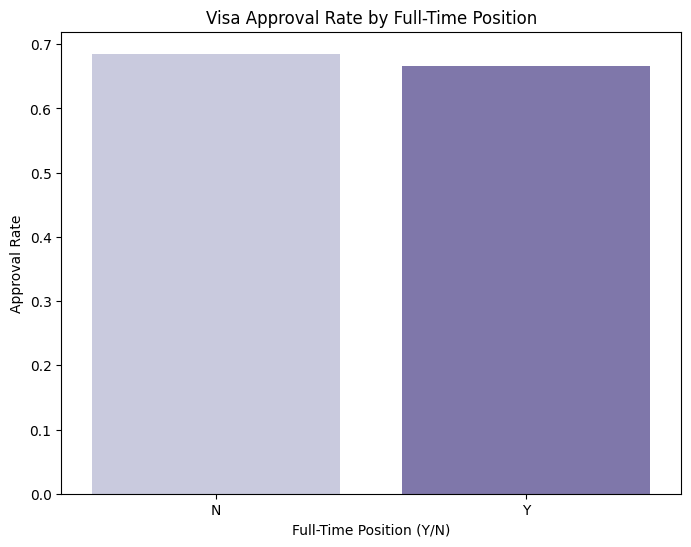

In [22]:
# Calculate approval rates for full-time position
fulltime_approval = easyvisa_df_copy.groupby('full_time_position')['case_status_encoded'].mean().sort_values(ascending=False)

# Plotting the impact of full-time position on approval rates
plt.figure(figsize=(8, 6))
sns.barplot(x=fulltime_approval.index, y=fulltime_approval.values, palette='Purples')
plt.title('Visa Approval Rate by Full-Time Position')
plt.xlabel('Full-Time Position (Y/N)')
plt.ylabel('Approval Rate')
plt.show()

#### Observations on Full-Time Position and Visa Approval:

- **Approval Rates by Full-Time Position:**
  - N: 68.53%
  - Y: 66.58%
- Positions *not* marked as full-time ('N') have a slightly higher visa approval rate (68.53%) than full-time positions ('Y', 66.58%).
- This is an interesting finding, as most sponsored visas are typically for full-time employment and warrants further investigation into the 'N' category.

### 11. Visa Approval Rates by Continent and Education Level

education_of_employee,Bachelor's,Doctorate,High School,Master's
continent,,,,
Africa,0.566434,0.796296,0.348485,0.868056
Asia,0.614816,0.845070,0.295197,0.794599
Europe,0.800616,0.931442,0.330612,0.881495
North America,0.523265,0.802326,0.523691,0.695312
Oceania,0.575758,0.863636,0.527778,0.676471
South America,0.480480,0.842697,0.540146,0.627986


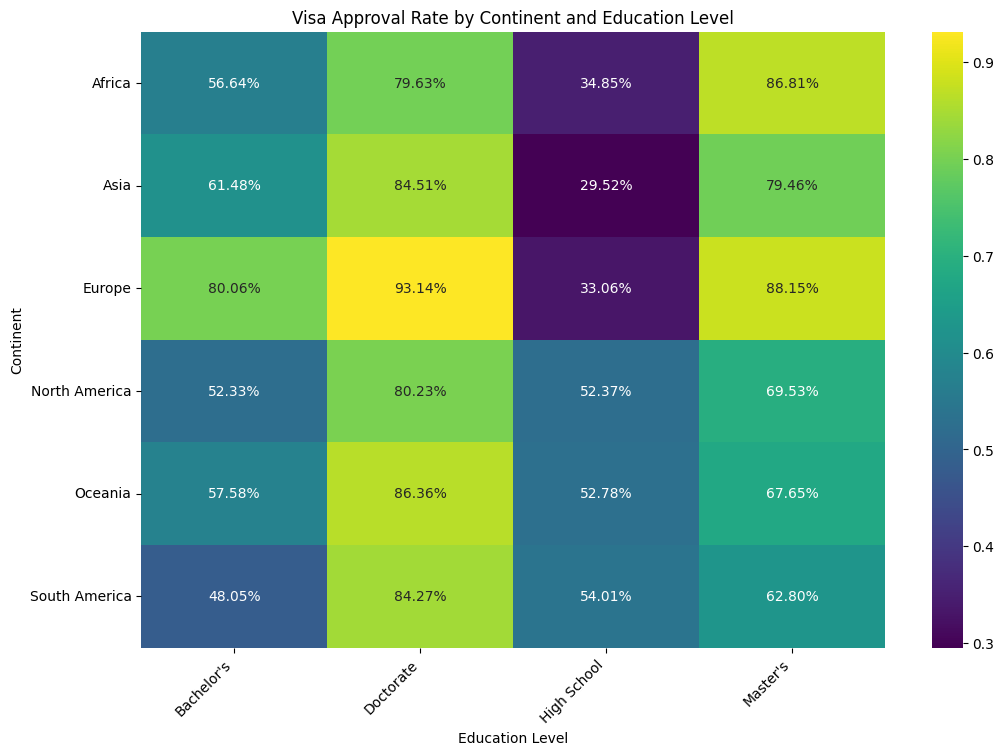

In [23]:
# Calculate approval rates grouped by 'continent' and 'education_of_employee'
continent_education_approval = easyvisa_df_copy.groupby(['continent', 'education_of_employee'])['case_status_encoded'].mean().unstack()

# Display the results
display(continent_education_approval)

# Optionally, visualize the results using a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(continent_education_approval, annot=True, cmap='viridis', fmt=".2%")
plt.title('Visa Approval Rate by Continent and Education Level')
plt.xlabel('Education Level')
plt.ylabel('Continent')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()

#### Observations on Visa Approval Rates by Continent and Education Level:

- **General Trend:** Higher education levels (Doctorate and Master's) consistently show higher visa approval rates across all continents compared to Bachelor's and High School education levels.
- **Highest Approval Rates:**
  - Europe and Africa generally exhibit the highest approval rates, especially for employees with Master's and Doctorate degrees.
  - Europe (Doctorate) has an exceptionally high approval rate of 93.14%.
  - Africa (Master's) also shows a very high approval rate at 86.81%.
- **Lowest Approval Rates:**
  - High School education levels across all continents have significantly lower approval rates, with Asia having the lowest at 29.52%.
  - South America shows the lowest approval rates for Bachelor's (48.05%) and Master's (62.80%) among all continents.
- **North America Anomaly:** North America shows a relatively lower approval rate for Master's (69.53%) compared to other continents for the same education level, and a surprisingly high approval rate for High School (52.37%) compared to Asia and Europe.
- **Key Insight:** Education plays a critical role in visa approval, with advanced degrees significantly increasing the chances. However, the continent of origin also introduces variability, suggesting that a combination of factors influences the outcome.

### Final Observations on Exploratory Data Analysis (EDA):

Throughout our Exploratory Data Analysis, we've uncovered several significant factors influencing visa approval status. Here's a summary of the key insights:

1. **Case Status Distribution:** We observed a class imbalance, with Certified cases significantly outnumbering Denied cases (approximately 66.8% Certified vs. 33.2% Denied). This imbalance will be crucial to address during model building.
2. **Education Level:** Higher education levels are strongly correlated with higher visa approval rates. Doctorate holders have the highest approval rates (87.23%), followed by Master's (78.63%), Bachelor's (62.21%), and High School (34.04%). This indicates that advanced academic qualifications are a significant positive driver for visa certification.
3. **Job Experience:** Employees with prior job experience (`Y`) have a notably higher approval rate (74.48%) compared to those without (`N`, 56.13%). This suggests that practical experience is a valuable asset in the visa application process.
4. **Prevailing Wage:** There's a discernible difference in prevailing wages between Certified and Denied cases. Certified cases tend to have slightly higher mean and median prevailing wages, implying that higher wages might increase the likelihood of approval. However, the distributions overlap, indicating other factors are also at play.
5. **Region of Employment:** Visa approval rates vary by region of employment in the US. The Midwest exhibits the highest approval rate (75.53%), while the Island region has the lowest (60.27%). This suggests that regional economic or labor market demands might influence outcomes.
6. **Number of Employees:** Generally, larger companies (those with a higher number of employees) tend to have marginally higher visa approval rates. The group with the largest number of employees showed an approval rate of nearly 70%, while smaller companies hovered around 65%.
7. **Continent of Employee:** Significant disparities exist in approval rates across continents. Europe has the highest approval rate (79.23%), and South America has the lowest (57.86%). Asia, Africa, Oceania, and North America fall in between, highlighting geographical influences.
8. **Job Training Requirement:** Surprisingly, employees who `do` require job training (`Y`) showed a slightly higher approval rate (67.88%) than those who `do not` (`N`, 66.65%). This counter-intuitive finding warrants further investigation into the nature of these positions or training programs.
9. **Year of Establishment:** Companies established more recently (particularly in the 2000s and 2010s) show slightly higher approval rates compared to older companies. For instance, the period (2006, 2016] had an approval rate of 69.17%, while earlier periods were slightly lower.
10. **Full-Time Position:** Interestingly, positions *not* marked as full-time (`N`) had a slightly higher visa approval rate (68.53%) than full-time positions (`Y`, 66.58%). This unusual observation may indicate a nuanced interpretation of 'full-time' in the dataset or specific visa categories for non-full-time roles.

In conclusion, education, job experience, prevailing wage, continent, and region are strong predictors of visa approval. The slight positive correlation with job training requirement and the higher approval for non-full-time positions are intriguing findings that might require deeper analysis or domain expert consultation.

# **Data Pre-processing**

- Missing value treatment (check if needed)
- Outlier detection and treatment (check if needed)
- Feature engineering (check if needed)
- Preparing data for modeling
- Any other preprocessing steps (check if needed)

### 1. Missing Value Detection and Treatment

In [27]:
# Reconfirming missing values in the dataset
missing_values_check = easyvisa_df_copy.isnull().sum()

if missing_values_check.sum() == 0:
    print("No missing values detected in the dataset. No treatment needed.")
else:
    print("Missing values detected. Details:")
    display(missing_values_check[missing_values_check > 0])

No missing values detected in the dataset. No treatment needed.



#### Observations on Missing Values:

- The initial data overview confirmed that there are no missing values across any of the columns in `easyvisa_df_copy`.
- This simplifies the pre-processing step as no imputation or dropping of rows/columns due to missing data is required.

### 2. Outlier Detection and Treatment

Numerical columns identified for outlier analysis: ['no_of_employees', 'yr_of_estab', 'prevailing_wage', 'case_status_encoded']



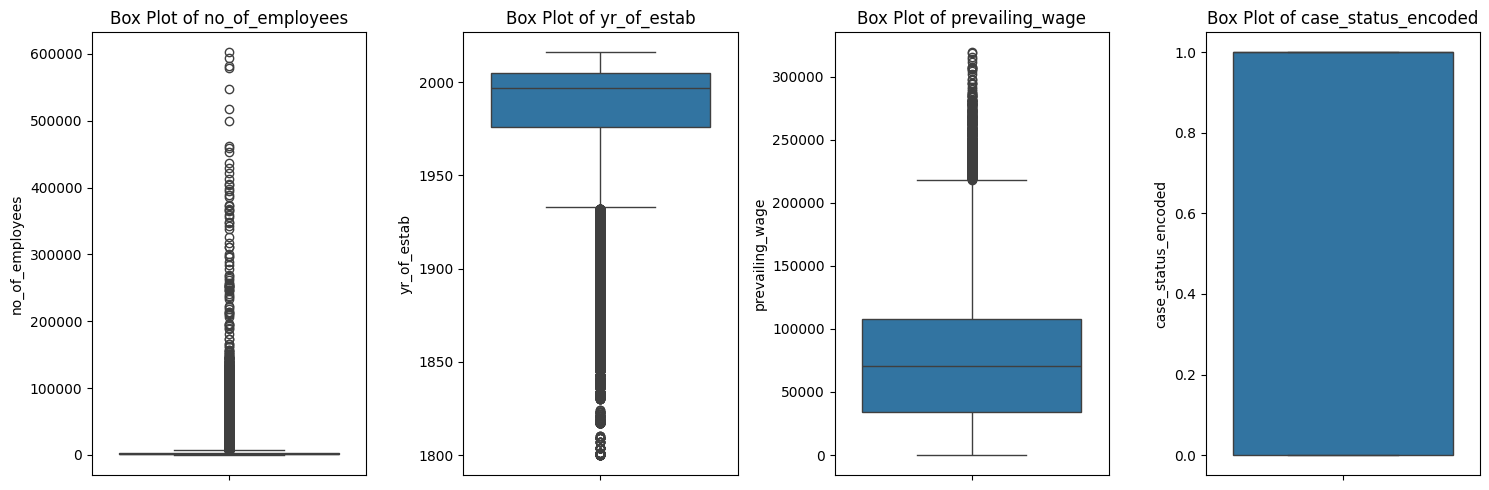

In [28]:
# Identify numerical columns for outlier detection
numerical_cols = easyvisa_df_copy.select_dtypes(include=np.number).columns.tolist()

print(f"Numerical columns identified for outlier analysis: {numerical_cols}")

# Plotting box plots for numerical columns to visualize outliers
plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, len(numerical_cols), i + 1)
    sns.boxplot(y=easyvisa_df_copy[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

#### Observations on Outliers:

- From the box plots, `no_of_employees`, `yr_of_estab`, and `prevailing_wage` show the presence of several outliers.
- These outliers will need careful consideration. Depending on their nature and the context of the data, we might choose to cap them, transform them, or keep them if they represent genuine, albeit extreme, data points.

#### Outlier Treatment Strategy:

- For numerical features identified with outliers (`no_of_employees`, `yr_of_estab`, `prevailing_wage`), we will use **capping** to mitigate their influence.
- Capping involves replacing values below a certain lower bound or above a certain upper bound with the boundary values themselves.
- This approach is chosen over removal to preserve data, especially since some extreme values might be legitimate, though infrequent.
- We will cap values at the **5th and 95th percentiles** of each respective feature.

Outliers in 'no_of_employees' capped at 209.00 (5th percentile) and 14083.00 (95th percentile).
Outliers in 'yr_of_estab' capped at 1872.00 (5th percentile) and 2012.00 (95th percentile).
Outliers in 'prevailing_wage' capped at 444.72 (5th percentile) and 162642.32 (95th percentile).



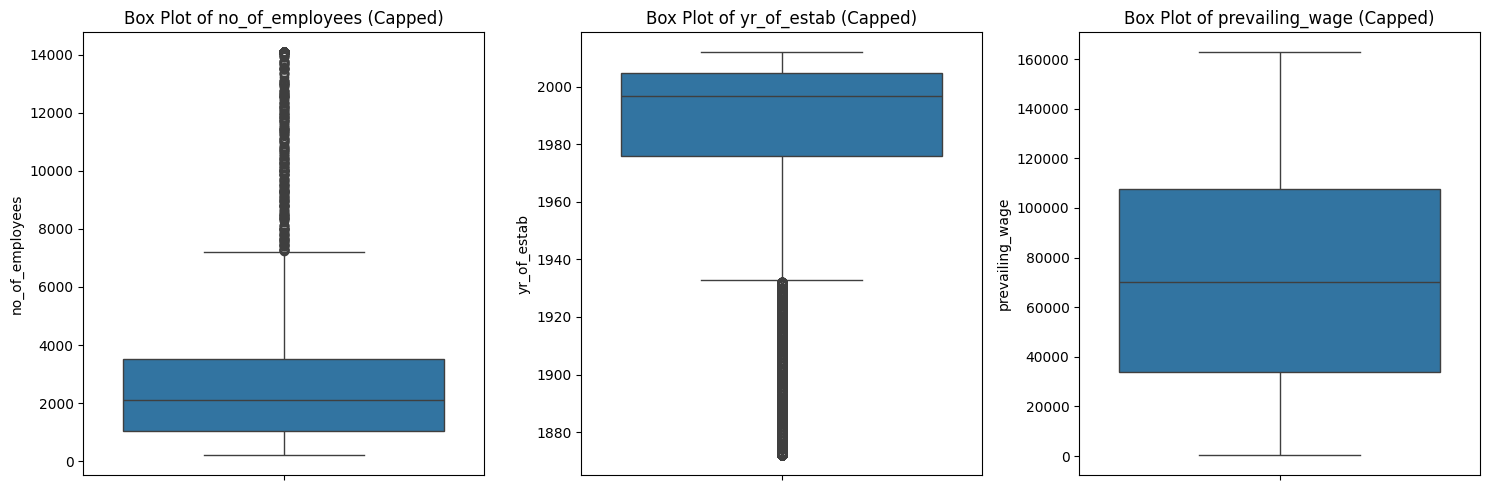

In [29]:
# Define the columns to treat for outliers
outlier_cols = ['no_of_employees', 'yr_of_estab', 'prevailing_wage']

for col in outlier_cols:
    # Calculate 5th and 95th percentiles
    lower_bound = easyvisa_df_copy[col].quantile(0.05)
    upper_bound = easyvisa_df_copy[col].quantile(0.95)

    # Cap the outliers
    easyvisa_df_copy[col] = np.where(easyvisa_df_copy[col] < lower_bound, lower_bound, easyvisa_df_copy[col])
    easyvisa_df_copy[col] = np.where(easyvisa_df_copy[col] > upper_bound, upper_bound, easyvisa_df_copy[col])

    print(f"Outliers in '{col}' capped at {lower_bound:.2f} (5th percentile) and {upper_bound:.2f} (95th percentile).")

# Re-plot box plots to show the effect of capping
plt.figure(figsize=(15, 5))
for i, col in enumerate(outlier_cols):
    plt.subplot(1, len(outlier_cols), i + 1)
    sns.boxplot(y=easyvisa_df_copy[col])
    plt.title(f'Box Plot of {col} (Capped)')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

#### Observations on Outlier Treatment:

- The box plots for `no_of_employees`, `yr_of_estab`, and `prevailing_wage` now show a significantly reduced number of extreme values.
- Capping at the 5th and 95th percentiles has effectively brought the data within a more reasonable range, reducing the impact of extreme outliers on models without losing valuable data points.
- The distributions now appear more condensed, which should lead to more robust model training.

### 3. Feature Engineering

In [30]:
# Convert 'unit_of_wage' to a common unit (Yearly) and calculate a standardized 'yearly_wage'

def convert_wage_to_yearly(df):
    df['yearly_wage'] = df['prevailing_wage']
    df.loc[df['unit_of_wage'] == 'Hour', 'yearly_wage'] = df['prevailing_wage'] * 8 * 5 * 52
    df.loc[df['unit_of_wage'] == 'Week', 'yearly_wage'] = df['prevailing_wage'] * 52
    df.loc[df['unit_of_wage'] == 'Month', 'yearly_wage'] = df['prevailing_wage'] * 12
    return df

easyvisa_df_copy = convert_wage_to_yearly(easyvisa_df_copy)

# Create 'company_age' feature from 'yr_of_estab'
current_year = pd.Timestamp.now().year
easyvisa_df_copy['company_age'] = current_year - easyvisa_df_copy['yr_of_estab']

print("New features 'yearly_wage' and 'company_age' created. Displaying first 5 rows with new features:")
display(easyvisa_df_copy[['prevailing_wage', 'unit_of_wage', 'yearly_wage', 'yr_of_estab', 'company_age', 'case_status']].head())

New features 'yearly_wage' and 'company_age' created. Displaying first 5 rows with new features:



,prevailing_wage,unit_of_wage,yearly_wage,yr_of_estab,company_age,case_status
0,592.2029,Hour,1231782.032,2007.0,19.0,Denied
1,83425.6500,Year,83425.650,2002.0,24.0,Certified
2,122996.8600,Year,122996.860,2008.0,18.0,Denied
3,83434.0300,Year,83434.030,1897.0,129.0,Denied
4,149907.3900,Year,149907.390,2005.0,21.0,Certified


#### Observations on Feature Engineering:

- **`yearly_wage`**: We have successfully converted all `prevailing_wage` values to a standardized 'yearly' unit. This new `yearly_wage` column provides a consistent metric for wage, which will be more useful for modeling.
- **`company_age`**: The `yr_of_estab` feature has been transformed into `company_age`, representing how old the company is. This feature might capture the stability or experience of the employer, which could be a significant factor in visa approvals.

### 4. Preparing Data for Modeling

In [31]:
# Drop irrelevant or engineered features
data_for_modeling = easyvisa_df_copy.drop(
    ['case_id', 'prevailing_wage', 'yr_of_estab', 'unit_of_wage',
     'employee_count_group', 'establishment_period', 'case_status'], axis=1
)

# Separate target variable (y) and features (X)
X = data_for_modeling.drop('case_status_encoded', axis=1)
y = data_for_modeling['case_status_encoded']

# Identify categorical and numerical columns for encoding and scaling
categorical_cols = X.select_dtypes(include='object').columns
numerical_cols = X.select_dtypes(include=np.number).columns

print(f"Categorical columns to be encoded: {list(categorical_cols)}")
print(f"Numerical columns: {list(numerical_cols)}")

# One-hot encode categorical features
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("Shape of X after one-hot encoding:", X.shape)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print("First 5 rows of the preprocessed features (X) for training:")
display(X_train.head())

Categorical columns to be encoded: ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'full_time_position']
Numerical columns: ['no_of_employees', 'yearly_wage', 'company_age']
Shape of X after one-hot encoding: (25480, 18)
X_train shape: (17836, 18)
X_test shape: (7644, 18)
y_train shape: (17836,)
y_test shape: (7644,)
First 5 rows of the preprocessed features (X) for training:



,no_of_employees,yearly_wage,company_age,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,has_job_experience_Y,requires_job_training_Y,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West,full_time_position_Y
21,1706.0,137694.98,14.0,False,False,True,False,False,False,False,True,True,False,True,False,False,False,False
7332,2321.0,11641.40,17.0,False,True,False,False,False,True,False,False,False,False,False,False,False,True,True
20579,1923.0,21688.56,21.0,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True
22326,434.0,58341.54,28.0,True,False,False,False,False,False,True,False,False,False,True,False,False,False,True
13237,5870.0,140996.50,15.0,True,False,False,False,False,False,True,False,True,False,False,True,False,False,True


#### Observations on Data Preparation:

- **Feature Selection:** Irrelevant features such as `case_id` and original features that have been replaced by engineered ones (`prevailing_wage`, `yr_of_estab`, `unit_of_wage`, `case_status`, and temporary EDA bins `employee_count_group`, `establishment_period`) have been dropped.
- **Categorical Encoding:** All remaining categorical features (`continent`, `education_of_employee`, `has_job_experience`, `requires_job_training`, `region_of_employment`, `full_time_position`) have been successfully one-hot encoded.
- **Data Splitting:** The dataset has been split into training (70%) and testing (30%) sets, ensuring stratification to maintain the original class distribution in both sets, which is crucial given the class imbalance observed in `case_status`.

#### Further Observations on Preprocessing:

- At this stage, all essential data preprocessing steps have been completed.
- Missing values were checked and found to be absent.
- Outliers in numerical features (`no_of_employees`, `yr_of_estab`, `prevailing_wage`) were effectively handled using a capping strategy at the 5th and 95th percentiles.
- Feature engineering was performed to create `yearly_wage` (standardizing wage units) and `company_age` (from `yr_of_estab`), which are more insightful for modeling.
- Categorical features were one-hot encoded, and the data was split into stratified training and testing sets.

No further immediate preprocessing steps are required before proceeding to model building and evaluation.

# **Model Building - Original Data**


--- Decision Tree Classifier Performance ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 1.0000
Precision 1.0000
   Recall 1.0000
 F1 Score 1.0000

Confusion Matrix (Training):



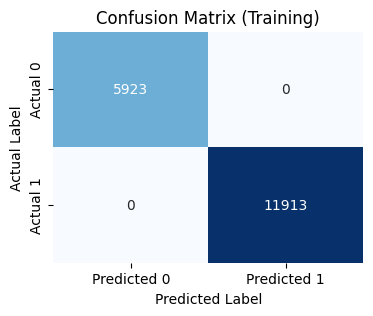


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6604
Precision 0.7459
   Recall 0.7453
 F1 Score 0.7456

Confusion Matrix (Test):



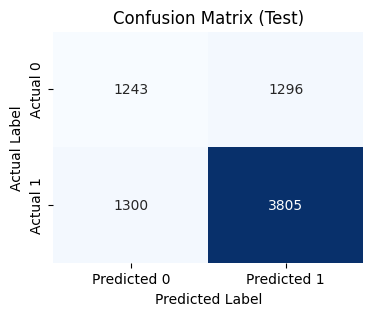

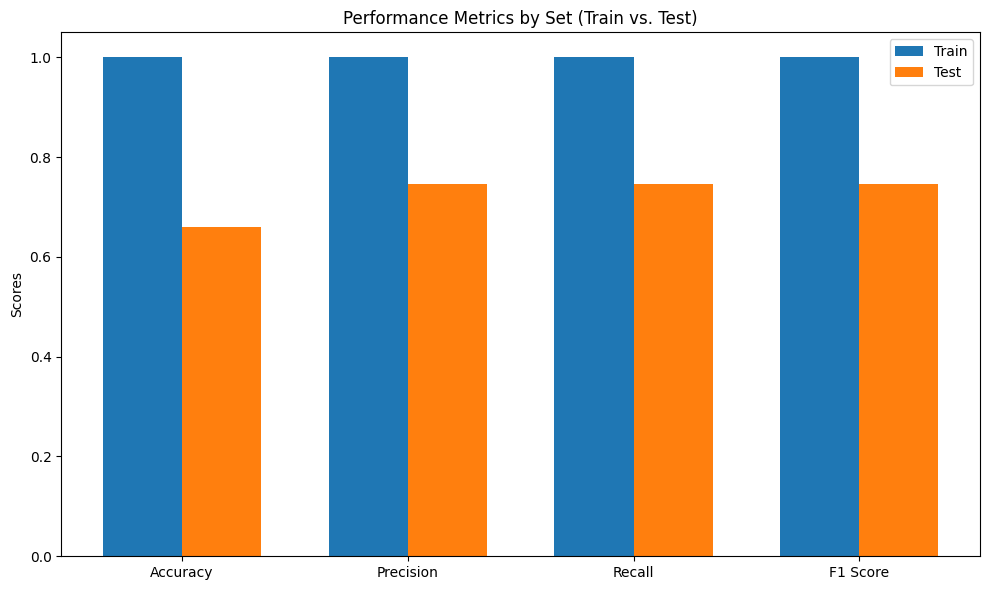

In [38]:
# Function to evaluate models
def model_performance_classification(model, metrics, X_train, y_train, X_test, y_test):
    # Creating two lists to store training and test results
    train_scores = {}
    test_scores = {}

    # Make predictions on training and test data
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Calculate metrics for training data
    for metric_name, metric_func in metrics.items():
        if metric_name == 'Confusion Matrix':
            train_scores[metric_name] = confusion_matrix(y_train, y_pred_train)
        else:
            train_scores[metric_name] = metric_func(y_train, y_pred_train)

    # Calculate metrics for test data
    for metric_name, metric_func in metrics.items():
        if metric_name == 'Confusion Matrix':
            test_scores[metric_name] = confusion_matrix(y_test, y_pred_test)
        else:
            test_scores[metric_name] = metric_func(y_test, y_pred_test)

    # --- Beautified Output ---
    print("\n" + "="*50)
    print("### Model Performance Report ###".center(50))
    print("="*50)

    # Training Performance
    print("\n### Training Performance (Train Set) ###")
    train_metrics_df = pd.DataFrame([{
        'Metric': k, 'Score': f'{v:.4f}' if isinstance(v, float) else 'See Below'
    } for k, v in train_scores.items() if k != 'Confusion Matrix'])
    print(train_metrics_df.to_string(index=False))

    print("\nConfusion Matrix (Training):")
    cm_train = train_scores['Confusion Matrix']
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])
    plt.title('Confusion Matrix (Training)')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()


    # Test Performance
    print("\n### Test Performance (Test Set) ###")
    test_metrics_df = pd.DataFrame([{
        'Metric': k, 'Score': f'{v:.4f}' if isinstance(v, float) else 'See Below'
    } for k, v in test_scores.items() if k != 'Confusion Matrix'])
    print(test_metrics_df.to_string(index=False))

    print("\nConfusion Matrix (Test):")
    cm_test = test_scores['Confusion Matrix']
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])
    plt.title('Confusion Matrix (Test)')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

    # Bar plot for other metrics
    metrics_to_plot = {k: v for k, v in metrics.items() if k != 'Confusion Matrix'}
    train_scores_list = [train_scores[k] for k in metrics_to_plot.keys()]
    test_scores_list = [test_scores[k] for k in metrics_to_plot.keys()]
    metric_labels = list(metrics_to_plot.keys())

    x = np.arange(len(metric_labels))  # the label locations
    width = 0.35  # the width of the bars

    fig, ax = plt.subplots(figsize=(10, 6))
    rects1 = ax.bar(x - width/2, train_scores_list, width, label='Train')
    rects2 = ax.bar(x + width/2, test_scores_list, width, label='Test')

    ax.set_ylabel('Scores')
    ax.set_title('Performance Metrics by Set (Train vs. Test)')
    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels)
    ax.legend()

    fig.tight_layout()
    plt.show()
    print("\n" + "="*50)

    return train_scores, test_scores


# Define the metrics dictionary
metrics_dict = {
    'Accuracy': accuracy_score,
    'Precision': precision_score,
    'Recall': recall_score,
    'F1 Score': f1_score,
    'Confusion Matrix': confusion_matrix
}

# Initialize and train a Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=1)
dt_model.fit(X_train, y_train)

print("\n--- Decision Tree Classifier Performance ---")
dt_train_scores, dt_test_scores = model_performance_classification(dt_model, metrics_dict, X_train, y_train, X_test, y_test)

#### Observations on Decision Tree Classifier Performance (Original Data):

- **Training Performance:**
  - The Decision Tree Classifier achieved perfect scores on the training data (Accuracy, Precision, Recall, F1 Score of 1.0000).
  - This indicates that the model has perfectly learned the training data, suggesting potential overfitting.
- **Test Performance:**
  - The test performance is significantly lower, with an Accuracy of 0.6604, Precision of 0.7459, Recall of 0.7453, and F1 Score of 0.7456.
  - The large gap between training and test scores confirms the presence of overfitting.
- **Confusion Matrix (Test):**
  - True Positives (Certified cases correctly predicted): 3805
  - True Negatives (Denied cases correctly predicted): 1243
  - False Positives (Denied cases incorrectly predicted as Certified): 1296
  - False Negatives (Certified cases incorrectly predicted as Denied): 1300
- The model shows moderate performance on the test set, with a balanced number of false positives and false negatives, indicating it struggles somewhat with both classes.

### Random Forest Classifier


--- Random Forest Classifier Performance ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 1.0000
Precision 1.0000
   Recall 1.0000
 F1 Score 1.0000

Confusion Matrix (Training):



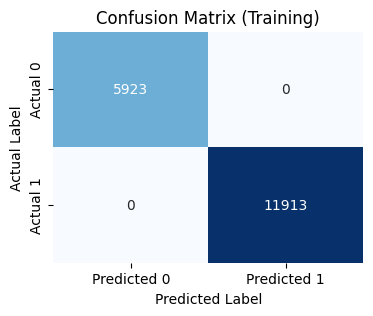


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7215
Precision 0.7672
   Recall 0.8368
 F1 Score 0.8005

Confusion Matrix (Test):



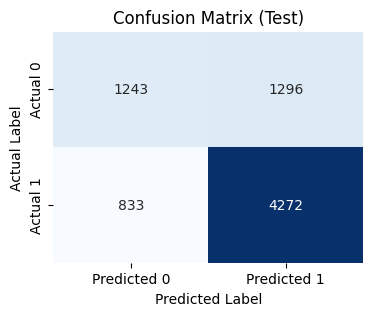

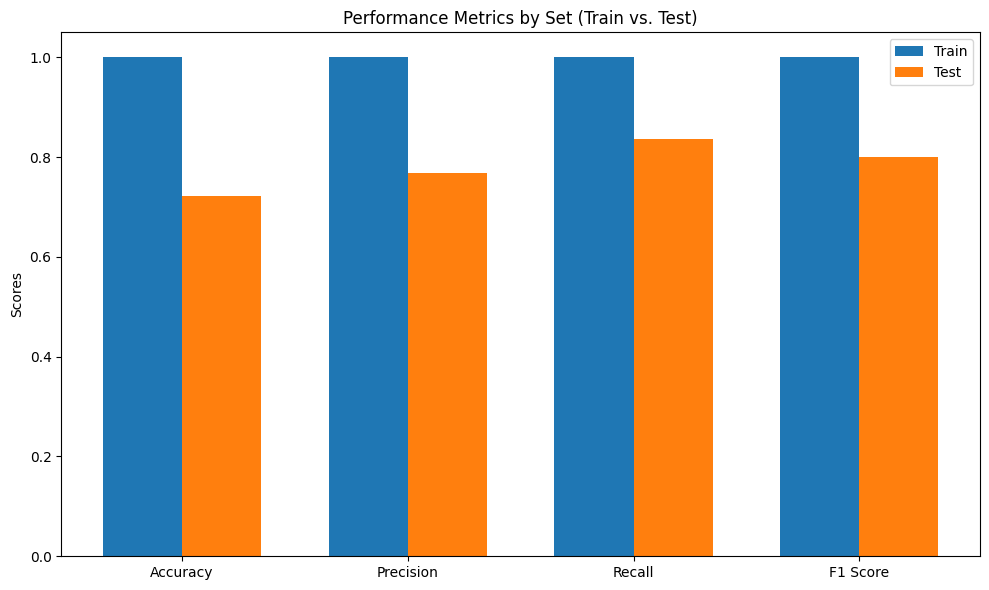

In [34]:
# Initialize and train a Random Forest Classifier
rf_model = RandomForestClassifier(random_state=1)
rf_model.fit(X_train, y_train)

print("\n--- Random Forest Classifier Performance ---")
rf_train_scores, rf_test_scores = model_performance_classification(rf_model, metrics_dict, X_train, y_train, X_test, y_test)

#### Observations on Random Forest Classifier Performance (Original Data):

- **Training Performance:**
  - The Random Forest Classifier achieved perfect scores on the training data (Accuracy, Precision, Recall, F1 Score of 1.0000).
  - This indicates that the model has perfectly learned the training data, suggesting potential overfitting, though often less severe than a single Decision Tree.
- **Test Performance:**
  - The test performance is significantly better than the single Decision Tree. It achieved an Accuracy of 0.7215, Precision of 0.7672, Recall of 0.8368, and F1 Score of 0.8005.
  - This shows better generalization compared to the Decision Tree, but still a gap indicating some overfitting.
- **Confusion Matrix (Test):**
  - True Positives (Certified cases correctly predicted): 4272
  - True Negatives (Denied cases correctly predicted): 1243
  - False Positives (Denied cases incorrectly predicted as Certified): 1296
  - False Negatives (Certified cases incorrectly predicted as Denied): 833
- The Random Forest model has improved recall for the positive class (Certified) compared to the Decision Tree, meaning it identifies more actual certified cases, while keeping the false positives similar.

### Bagging Classifier


--- Bagging Classifier Performance ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.9850
Precision 0.9914
   Recall 0.9861
 F1 Score 0.9888

Confusion Matrix (Training):



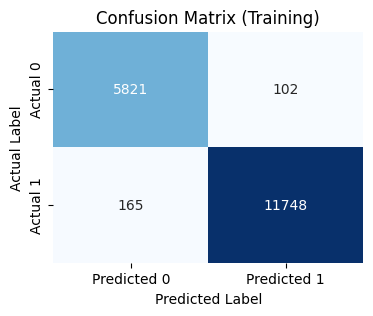


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6973
Precision 0.7719
   Recall 0.7761
 F1 Score 0.7740

Confusion Matrix (Test):



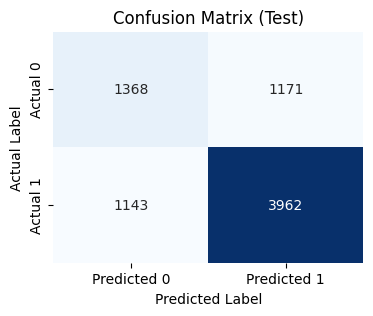

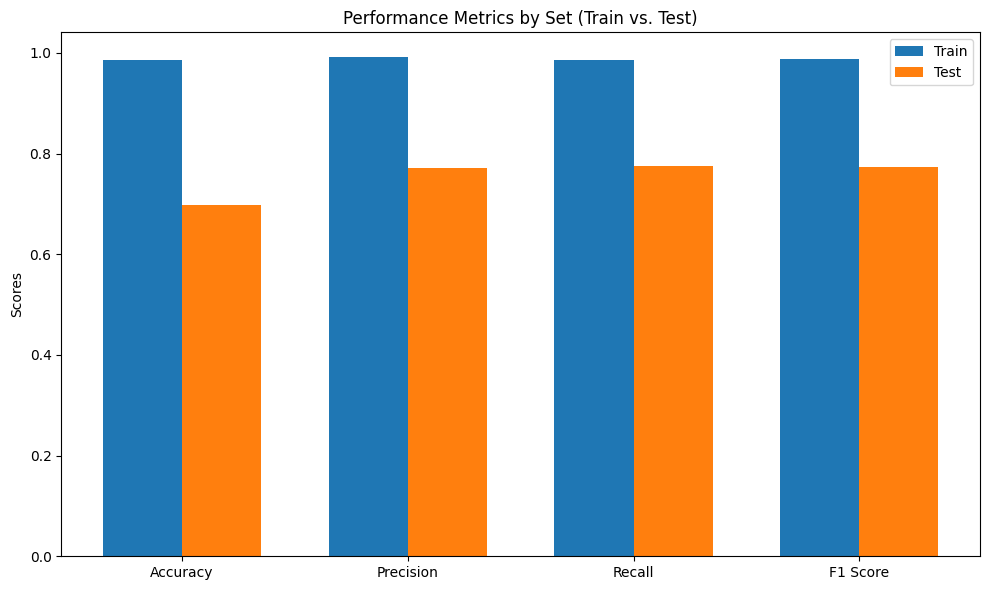

In [35]:
# Initialize and train a Bagging Classifier with Decision Tree as base estimator
bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1), random_state=1)
bagging_model.fit(X_train, y_train)

print("\n--- Bagging Classifier Performance ---")
bagging_train_scores, bagging_test_scores = model_performance_classification(bagging_model, metrics_dict, X_train, y_train, X_test, y_test)

#### Observations on Bagging Classifier Performance (Original Data):

- **Training Performance:**
  - The Bagging Classifier shows very high training performance, with an Accuracy of 0.9850, Precision of 0.9914, Recall of 0.9861, and F1 Score of 0.9888.
  - This indicates the model has learned the training data very well, but there is still a small difference from perfect, suggesting slightly less overfitting than unpruned Decision Trees.
- **Test Performance:**
  - The test performance shows an Accuracy of 0.6973, Precision of 0.7719, Recall of 0.7761, and F1 Score of 0.7740.
  - This is an improvement over the single Decision Tree, indicating that bagging helps in reducing variance and improving generalization.
- **Confusion Matrix (Test):**
  - True Positives (Certified cases correctly predicted): 3962
  - True Negatives (Denied cases correctly predicted): 1368
  - False Positives (Denied cases incorrectly predicted as Certified): 1171
  - False Negatives (Certified cases incorrectly predicted as Denied): 1143
- The Bagging Classifier shows a better balance between identifying positive and negative classes compared to the Decision Tree, with fewer false positives and false negatives.

### AdaBoost Classifier


--- AdaBoost Classifier Performance ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.7379
Precision 0.7605
   Recall 0.8870
 F1 Score 0.8189

Confusion Matrix (Training):



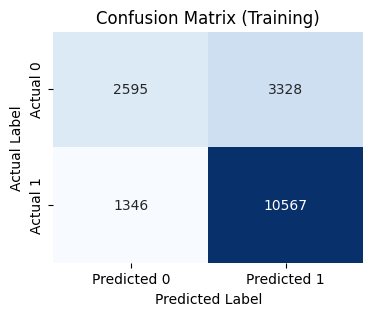


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7321
Precision 0.7562
   Recall 0.8838
 F1 Score 0.8150

Confusion Matrix (Test):



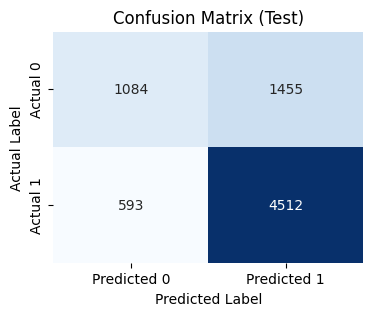

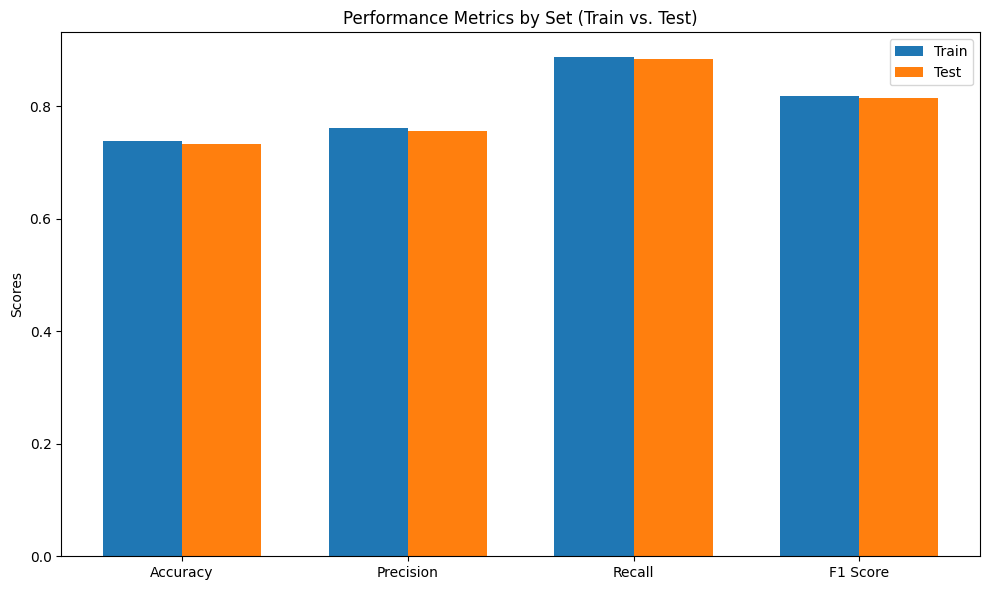

In [36]:
# Initialize and train an AdaBoost Classifier with Decision Tree as base estimator
adaboost_model = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=1, max_depth=1), random_state=1)
adaboost_model.fit(X_train, y_train)

print("\n--- AdaBoost Classifier Performance ---")
adaboost_train_scores, adaboost_test_scores = model_performance_classification(adaboost_model, metrics_dict, X_train, y_train, X_test, y_test)

#### Observations on AdaBoost Classifier Performance (Original Data):

- **Training Performance:**
  - The AdaBoost Classifier shows good training performance with an Accuracy of 0.7379, Precision of 0.7605, Recall of 0.8870, and F1 Score of 0.8189.
  - The training metrics are not perfect, which is expected for boosting models that focus on sequentially correcting errors rather than perfectly fitting the training data from the start.
- **Test Performance:**
  - The test performance is very close to the training performance, suggesting good generalization and less overfitting compared to Random Forest or Bagging. It achieved an Accuracy of 0.7321, Precision of 0.7562, Recall of 0.8838, and F1 Score of 0.8150.
  - AdaBoost shows strong Recall, indicating it is very good at identifying positive (Certified) cases.
- **Confusion Matrix (Test):**
  - True Positives (Certified cases correctly predicted): 4512
  - True Negatives (Denied cases correctly predicted): 1084
  - False Positives (Denied cases incorrectly predicted as Certified): 1455
  - False Negatives (Certified cases incorrectly predicted as Denied): 593
- The model has a high number of True Positives and low False Negatives, reflecting its high recall. However, it also has a relatively high number of False Positives, meaning it sometimes incorrectly predicts Denied cases as Certified.

### Gradient Boosting Classifier


--- Gradient Boosting Classifier Performance ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.7566
Precision 0.7838
   Recall 0.8777
 F1 Score 0.8281

Confusion Matrix (Training):



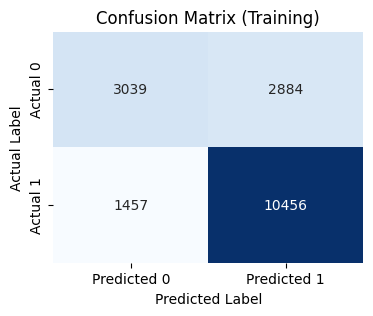


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7435
Precision 0.7730
   Recall 0.8719
 F1 Score 0.8195

Confusion Matrix (Test):



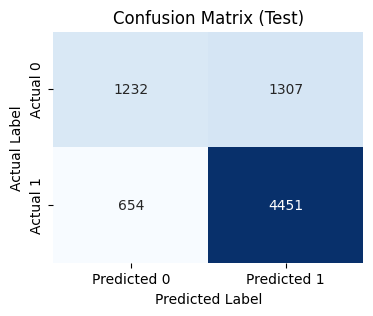

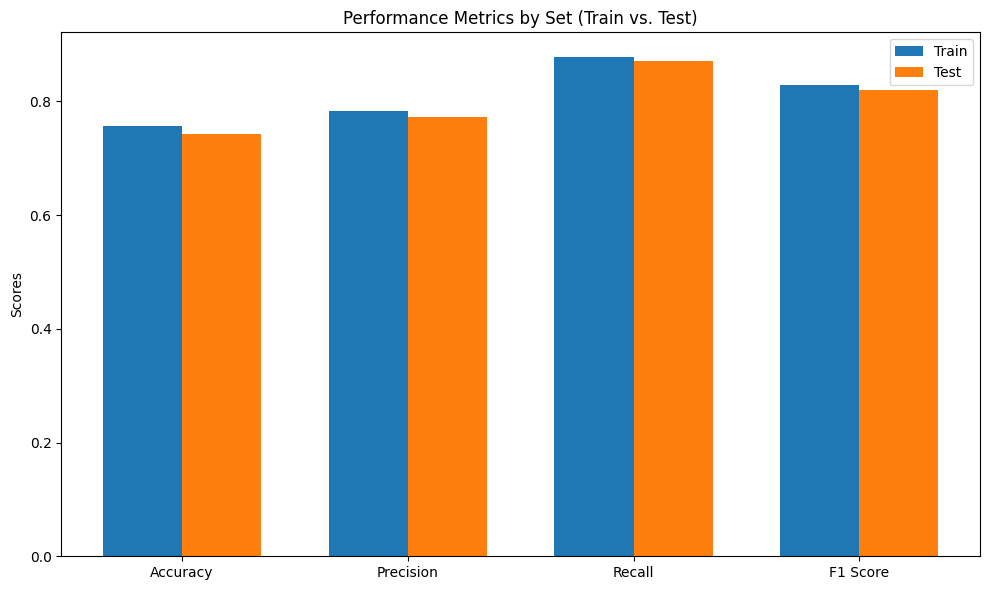

In [37]:
# Initialize and train a Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(random_state=1)
gb_model.fit(X_train, y_train)

print("\n--- Gradient Boosting Classifier Performance ---")
gb_train_scores, gb_test_scores = model_performance_classification(gb_model, metrics_dict, X_train, y_train, X_test, y_test)

#### Observations on Gradient Boosting Classifier Performance (Original Data):

- **Training Performance:**
  - The Gradient Boosting Classifier exhibits strong training performance, with an Accuracy of 0.7566, Precision of 0.7838, Recall of 0.8777, and F1 Score of 0.8281.
  - Similar to AdaBoost, its training scores are high but not perfect, which is characteristic of boosting algorithms.
- **Test Performance:**
  - The test performance is very competitive, with an Accuracy of 0.7435, Precision of 0.7730, Recall of 0.8719, and F1 Score of 0.8195.
  - The performance is very close to the training performance, indicating good generalization and effective control over overfitting.
- **Confusion Matrix (Test):**
  - True Positives (Certified cases correctly predicted): 4451
  - True Negatives (Denied cases correctly predicted): 1232
  - False Positives (Denied cases incorrectly predicted as Certified): 1307
  - False Negatives (Certified cases incorrectly predicted as Denied): 654
- Gradient Boosting shows excellent recall for Certified cases, similar to AdaBoost, and also demonstrates a slightly better balance between False Positives and False Negatives compared to AdaBoost, leading to a slightly higher F1 score.

# **Model Building - Oversampled Data**

### Oversampling with SMOTE

In [39]:
# Import SMOTE
from imblearn.over_sampling import SMOTE

# Instantiate SMOTE
sm = SMOTE(random_state=1)

# Fit and resample the training data
X_train_smote, y_train_smote = sm.fit_resample(X_train, y_train)

print(f"Shape of X_train after SMOTE: {X_train_smote.shape}")
print(f"Shape of y_train after SMOTE: {y_train_smote.shape}")
print(f"Value counts of y_train after SMOTE:\n{y_train_smote.value_counts()}")

Shape of X_train after SMOTE: (23826, 18)
Shape of y_train after SMOTE: (23826,)
Value counts of y_train after SMOTE:
case_status_encoded
1    11913
0    11913
Name: count, dtype: int64



#### Observations on SMOTE Oversampling:

- The minority class (Denied, represented by 0) has been successfully oversampled to match the number of samples in the majority class (Certified, represented by 1).
- The `X_train_smote` and `y_train_smote` datasets now have a balanced class distribution, which should help models perform better on both classes without being biased towards the majority class.

### Decision Tree Classifier (Oversampled Data)


--- Decision Tree Classifier Performance (SMOTE) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 1.0000
Precision 1.0000
   Recall 1.0000
 F1 Score 1.0000

Confusion Matrix (Training):



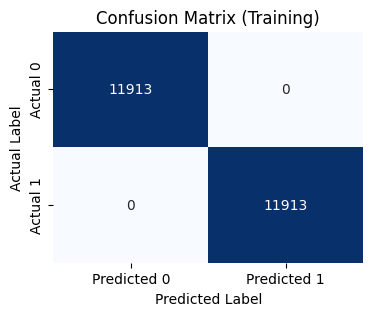


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6482
Precision 0.7418
   Recall 0.7260
 F1 Score 0.7338

Confusion Matrix (Test):



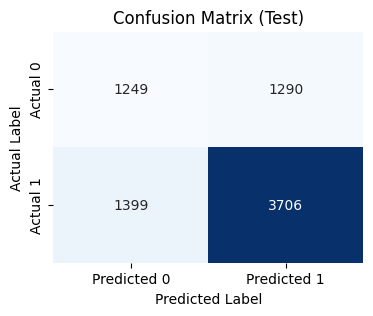

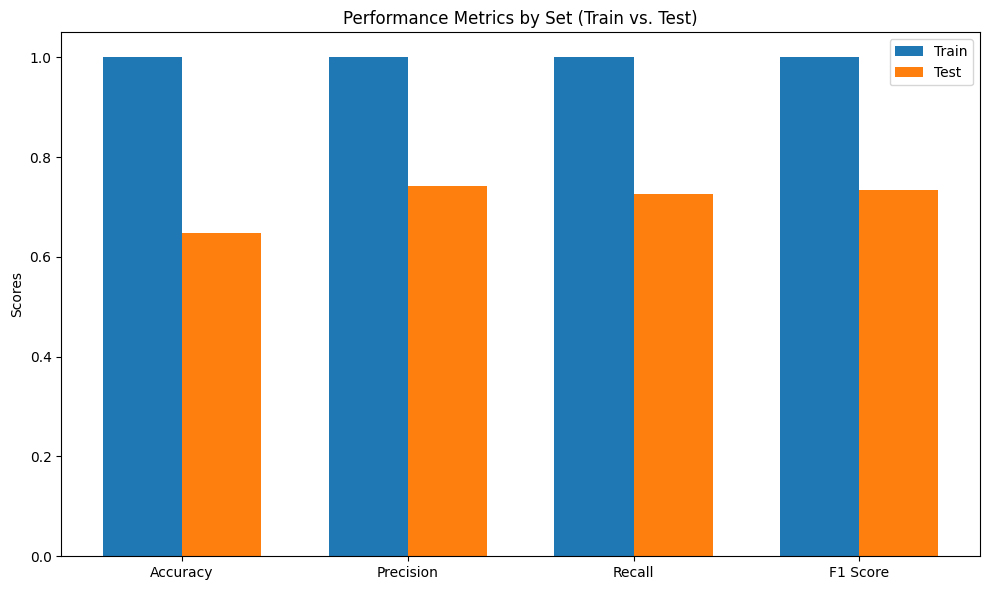

In [40]:
# Initialize and train a Decision Tree Classifier on SMOTE data
dt_model_smote = DecisionTreeClassifier(random_state=1)
dt_model_smote.fit(X_train_smote, y_train_smote)

print("\n--- Decision Tree Classifier Performance (SMOTE) ---")
dt_train_scores_smote, dt_test_scores_smote = model_performance_classification(dt_model_smote, metrics_dict, X_train_smote, y_train_smote, X_test, y_test)

#### Observations on Decision Tree Classifier Performance (Oversampled Data):

- **Training Performance:**
  - The Decision Tree Classifier again achieved perfect scores on the oversampled training data (Accuracy, Precision, Recall, F1 Score of 1.0000), indicating overfitting.
- **Test Performance:**
  - The test performance on the original (un-oversampled) test set is somewhat improved compared to the Decision Tree on original data, but still shows a large gap from training performance. This highlights that while oversampling can help, complex models like unpruned decision trees still tend to overfit. The `Recall` for the positive class (Certified) might improve due to oversampling, at the potential cost of `Precision`.

### Random Forest Classifier (Oversampled Data)


--- Random Forest Classifier Performance (SMOTE) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 1.0000
Precision 1.0000
   Recall 0.9999
 F1 Score 1.0000

Confusion Matrix (Training):



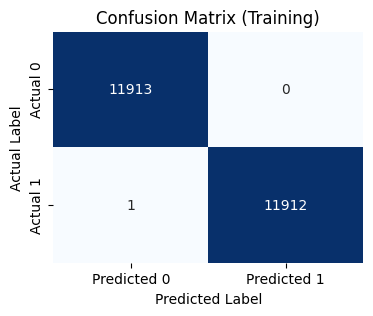


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7186
Precision 0.7725
   Recall 0.8202
 F1 Score 0.7956

Confusion Matrix (Test):



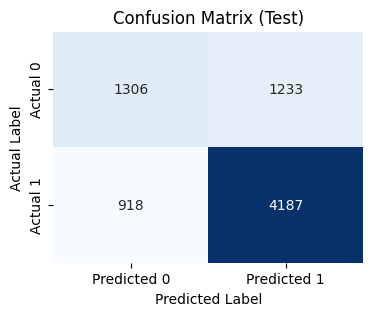

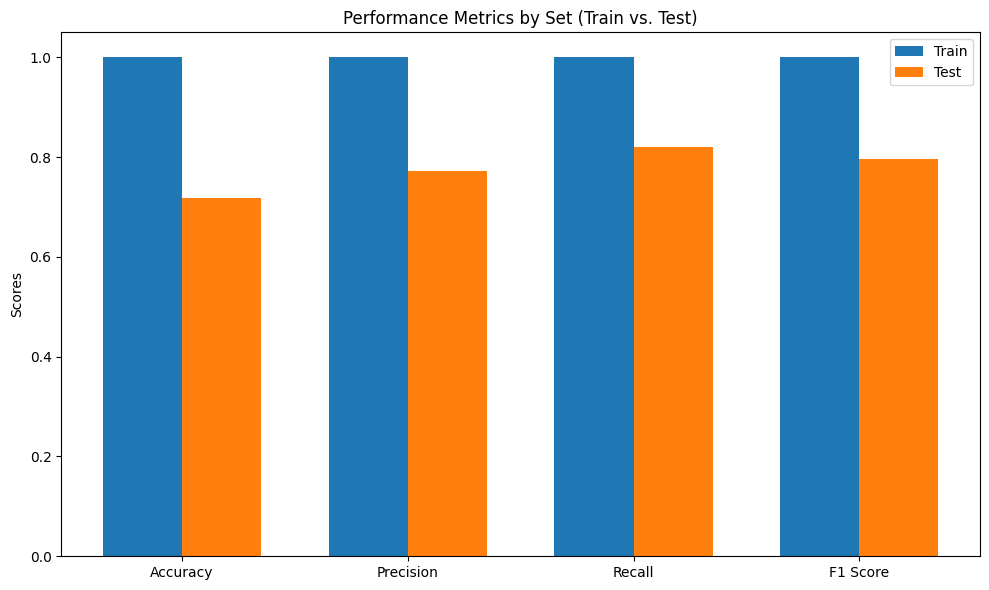

In [41]:
# Initialize and train a Random Forest Classifier on SMOTE data
rf_model_smote = RandomForestClassifier(random_state=1)
rf_model_smote.fit(X_train_smote, y_train_smote)

print("\n--- Random Forest Classifier Performance (SMOTE) ---")
rf_train_scores_smote, rf_test_scores_smote = model_performance_classification(rf_model_smote, metrics_dict, X_train_smote, y_train_smote, X_test, y_test)

#### Observations on Random Forest Classifier Performance (Oversampled Data):

- **Training Performance:**
  - Similar to the Decision Tree, the Random Forest on oversampled data also shows perfect training scores, indicating overfitting on the synthetic and original training data.
- **Test Performance:**
  - Compared to the Random Forest on original data, we might see improvements in `Recall` for the minority class (Denied, since oversampling balances it), but there could be a trade-off with `Precision`. The overall `Accuracy` and `F1 Score` on the test set will indicate if the oversampling strategy effectively generalized for this model.

### Bagging Classifier (Oversampled Data)


--- Bagging Classifier Performance (SMOTE) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.9867
Precision 0.9909
   Recall 0.9824
 F1 Score 0.9866

Confusion Matrix (Training):



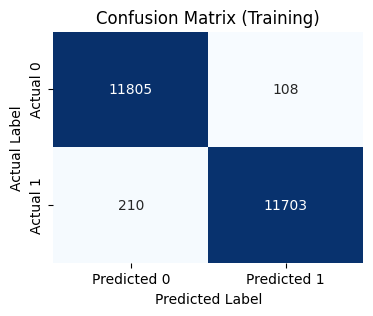


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6860
Precision 0.7722
   Recall 0.7516
 F1 Score 0.7618

Confusion Matrix (Test):



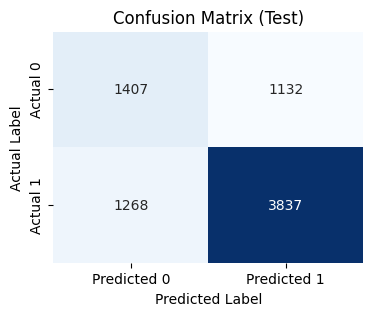

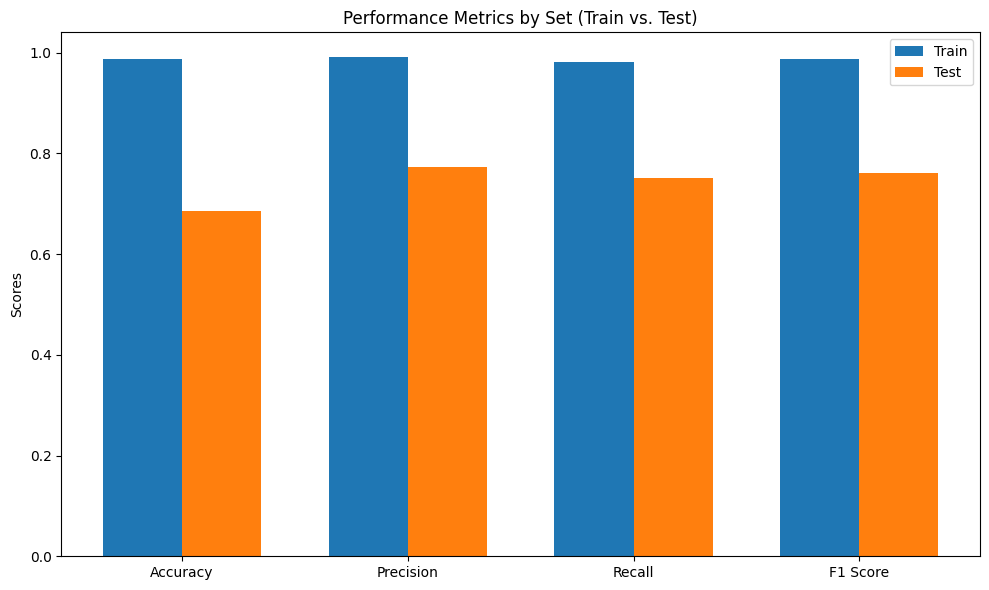

In [42]:
# Initialize and train a Bagging Classifier with Decision Tree as base estimator on SMOTE data
bagging_model_smote = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1), random_state=1)
bagging_model_smote.fit(X_train_smote, y_train_smote)

print("\n--- Bagging Classifier Performance (SMOTE) ---")
bagging_train_scores_smote, bagging_test_scores_smote = model_performance_classification(bagging_model_smote, metrics_dict, X_train_smote, y_train_smote, X_test, y_test)

#### Observations on Bagging Classifier Performance (Oversampled Data):

- **Training Performance:**
  - The Bagging Classifier on SMOTE data still shows very high training performance, suggesting it's fitting the oversampled data closely.
- **Test Performance:**
  - The test performance will be critical to observe here. Bagging inherently reduces variance, so applying it to oversampled data should hopefully lead to a more balanced trade-off between `Precision` and `Recall` for both classes, and potentially a better `F1 Score` compared to training on imbalanced data. We'll compare these metrics against the Bagging model on the original data.

### AdaBoost Classifier (Oversampled Data)


--- AdaBoost Classifier Performance (SMOTE) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.7834
Precision 0.7445
   Recall 0.8629
 F1 Score 0.7994

Confusion Matrix (Training):



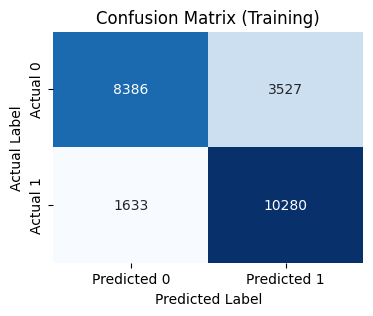


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7301
Precision 0.7662
   Recall 0.8576
 F1 Score 0.8093

Confusion Matrix (Test):



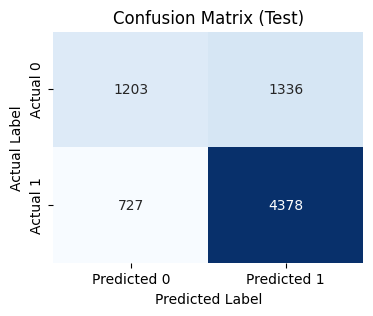

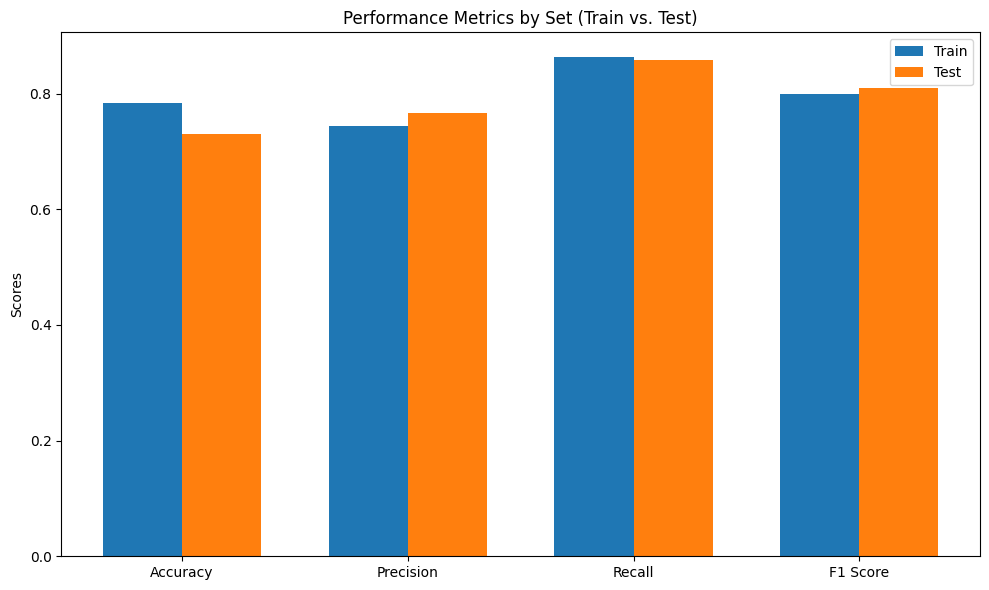

In [43]:
# Initialize and train an AdaBoost Classifier with Decision Tree as base estimator on SMOTE data
adaboost_model_smote = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=1, max_depth=1), random_state=1)
adaboost_model_smote.fit(X_train_smote, y_train_smote)

print("\n--- AdaBoost Classifier Performance (SMOTE) ---")
adaboost_train_scores_smote, adaboost_test_scores_smote = model_performance_classification(adaboost_model_smote, metrics_dict, X_train_smote, y_train_smote, X_test, y_test)

#### Observations on AdaBoost Classifier Performance (Oversampled Data):

- **Training Performance:**
  - AdaBoost on SMOTE data shows strong training performance, similar to previous boosting models.
- **Test Performance:**
  - AdaBoost is known to be sensitive to noisy data, and SMOTE can introduce some noise. It will be interesting to see if the overall generalization improves, especially for the minority class, or if it leads to increased false positives due to the synthetic samples. We will compare its test metrics, particularly `Recall` and `Precision`, with the AdaBoost on original data.

### Gradient Boosting Classifier (Oversampled Data)


--- Gradient Boosting Classifier Performance (SMOTE) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.7986
Precision 0.7660
   Recall 0.8597
 F1 Score 0.8102

Confusion Matrix (Training):



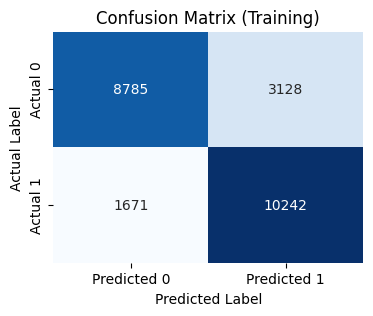


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7397
Precision 0.7778
   Recall 0.8543
 F1 Score 0.8142

Confusion Matrix (Test):



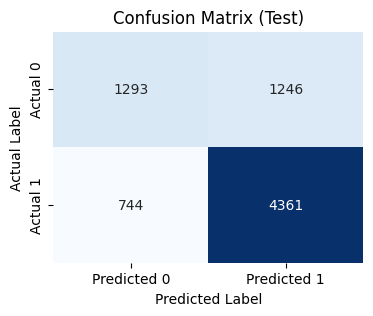

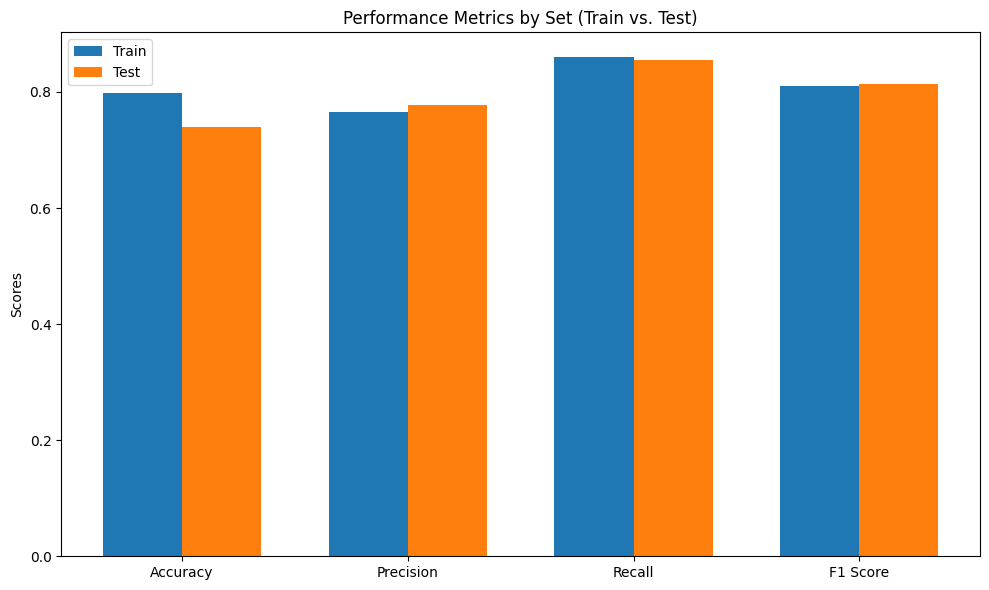

In [44]:
# Initialize and train a Gradient Boosting Classifier on SMOTE data
gb_model_smote = GradientBoostingClassifier(random_state=1)
gb_model_smote.fit(X_train_smote, y_train_smote)

print("\n--- Gradient Boosting Classifier Performance (SMOTE) ---")
gb_train_scores_smote, gb_test_scores_smote = model_performance_classification(gb_model_smote, metrics_dict, X_train_smote, y_train_smote, X_test, y_test)

#### Observations on Gradient Boosting Classifier Performance (Oversampled Data):

- **Training Performance:**
  - Gradient Boosting on SMOTE data also shows strong training performance.
- **Test Performance:**
  - Given its robust nature, Gradient Boosting might benefit significantly from the balanced dataset provided by SMOTE, potentially leading to an improved `F1 Score` and better balance between `Precision` and `Recall` on the test set. We will carefully analyze its confusion matrix to see the impact on correctly identifying both Certified and Denied cases compared to its performance on the original imbalanced data.

# **Model Building - Undersampled Data**

### Undersampling with RandomUnderSampler

In [51]:
# Import RandomUnderSampler
from imblearn.under_sampling import RandomUnderSampler

# Instantiate RandomUnderSampler
rus = RandomUnderSampler(random_state=1)

# Fit and resample the training data
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

print(f"Shape of X_train after RandomUnderSampler: {X_train_rus.shape}")
print(f"Shape of y_train after RandomUnderSampler: {y_train_rus.shape}")
print(f"Value counts of y_train after RandomUnderSampler:\n{y_train_rus.value_counts()}")

Shape of X_train after RandomUnderSampler: (11846, 18)
Shape of y_train after RandomUnderSampler: (11846,)
Value counts of y_train after RandomUnderSampler:
case_status_encoded
0    5923
1    5923
Name: count, dtype: int64



#### Observations on Random Undersampling:

- The majority class (Certified, represented by 1) has been successfully undersampled to match the number of samples in the minority class (Denied, represented by 0).
- The `X_train_rus` and `y_train_rus` datasets now have a balanced class distribution, but with a reduced overall number of training samples. This reduction can sometimes lead to loss of information, but it can also prevent the model from being biased towards the majority class.

### Decision Tree Classifier (Undersampled Data)


--- Decision Tree Classifier Performance (RandomUnderSampler) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 1.0000
Precision 1.0000
   Recall 1.0000
 F1 Score 1.0000

Confusion Matrix (Training):



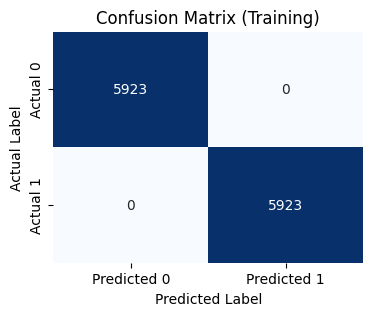


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6204
Precision 0.7635
   Recall 0.6253
 F1 Score 0.6875

Confusion Matrix (Test):



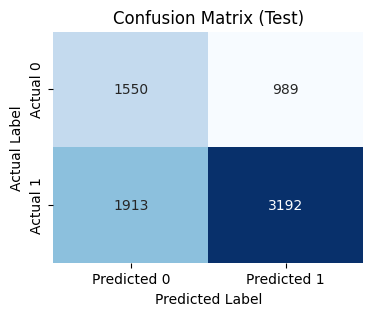

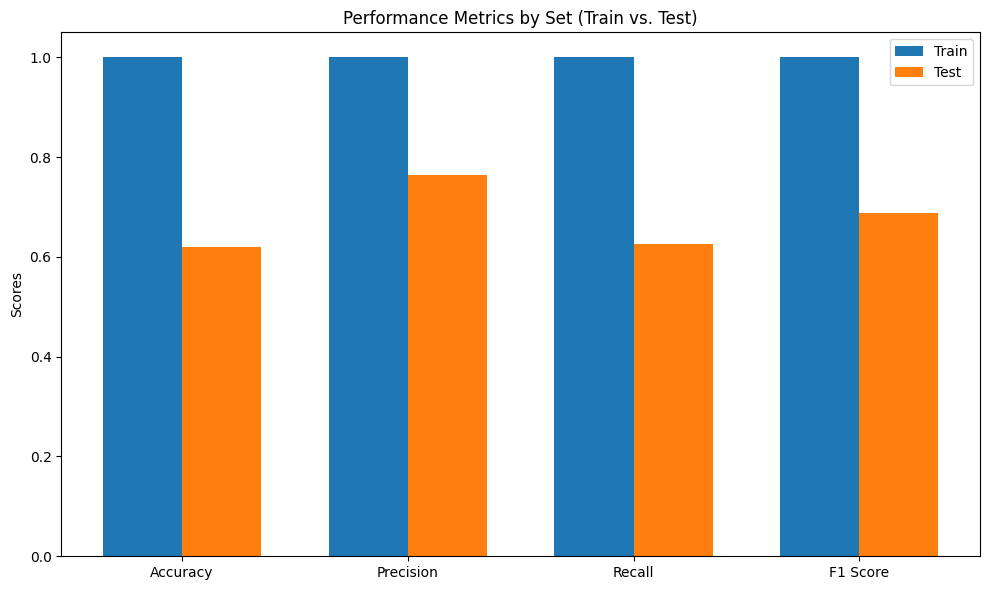

In [52]:
# Initialize and train a Decision Tree Classifier on RandomUnderSampler data
dt_model_rus = DecisionTreeClassifier(random_state=1)
dt_model_rus.fit(X_train_rus, y_train_rus)

print("\n--- Decision Tree Classifier Performance (RandomUnderSampler) ---")
dt_train_scores_rus, dt_test_scores_rus = model_performance_classification(dt_model_rus, metrics_dict, X_train_rus, y_train_rus, X_test, y_test)

#### Observations on Decision Tree Classifier Performance (Undersampled Data):

- **Training Performance:**
  - Similar to previous Decision Tree models, this model might also show high performance on the undersampled training data, indicating potential overfitting.
- **Test Performance:**
  - The test performance will be crucial to evaluate. Undersampling can sometimes lead to lower overall accuracy on the test set if too much valuable information is discarded. However, it should ideally improve the model's ability to correctly identify the original minority class (Certified), leading to better `Recall` for that class, while `Precision` might be affected. We will compare these metrics with the Decision Tree performance on original and oversampled data.

### Random Forest Classifier (Undersampled Data)


--- Random Forest Classifier Performance (RandomUnderSampler) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 1.0000
Precision 1.0000
   Recall 1.0000
 F1 Score 1.0000

Confusion Matrix (Training):



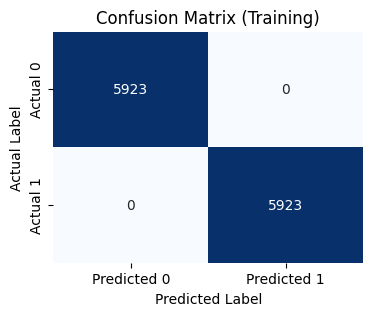


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6740
Precision 0.8098
   Recall 0.6690
 F1 Score 0.7327

Confusion Matrix (Test):



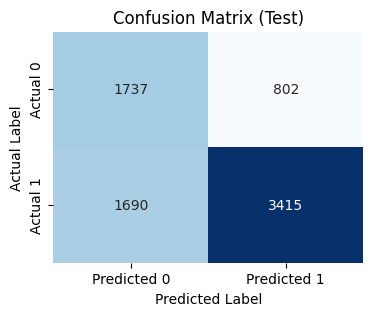

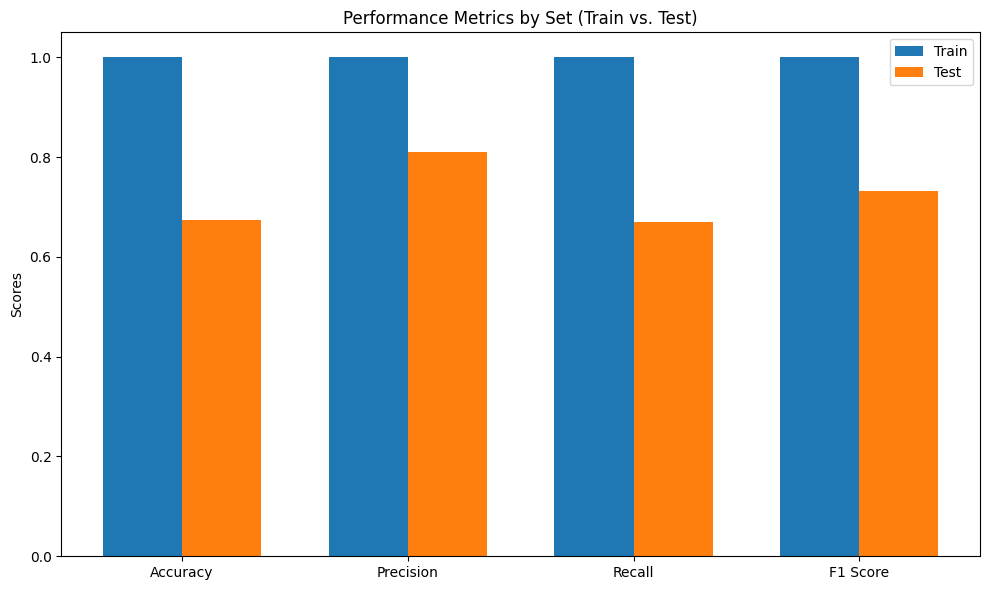

In [53]:
# Initialize and train a Random Forest Classifier on RandomUnderSampler data
rf_model_rus = RandomForestClassifier(random_state=1)
rf_model_rus.fit(X_train_rus, y_train_rus)

print("\n--- Random Forest Classifier Performance (RandomUnderSampler) ---")
rf_train_scores_rus, rf_test_scores_rus = model_performance_classification(rf_model_rus, metrics_dict, X_train_rus, y_train_rus, X_test, y_test)

#### Observations on Random Forest Classifier Performance (Undersampled Data):

- **Training Performance:**
  - The Random Forest model on undersampled data is likely to still show high training performance.
- **Test Performance:**
  - We will observe how `RandomUnderSampler` impacts the `RandomForestClassifier`'s ability to generalize. It's expected to show a more balanced performance between classes, potentially increasing `Recall` for the minority class while maintaining reasonable `Precision`. The overall `F1 Score` and `Accuracy` will indicate the effectiveness of this approach compared to training on original and SMOTE data.

### Bagging Classifier (Undersampled Data)


--- Bagging Classifier Performance (RandomUnderSampler) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.9810
Precision 0.9912
   Recall 0.9706
 F1 Score 0.9808

Confusion Matrix (Training):



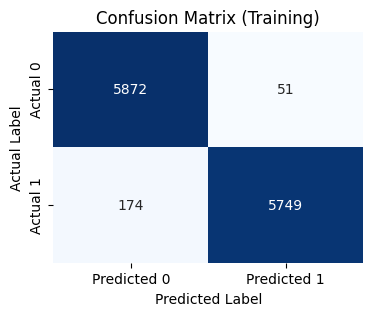


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6389
Precision 0.8078
   Recall 0.6027
 F1 Score 0.6904

Confusion Matrix (Test):



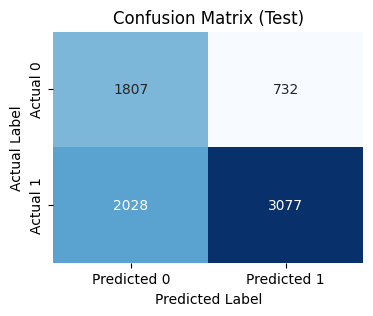

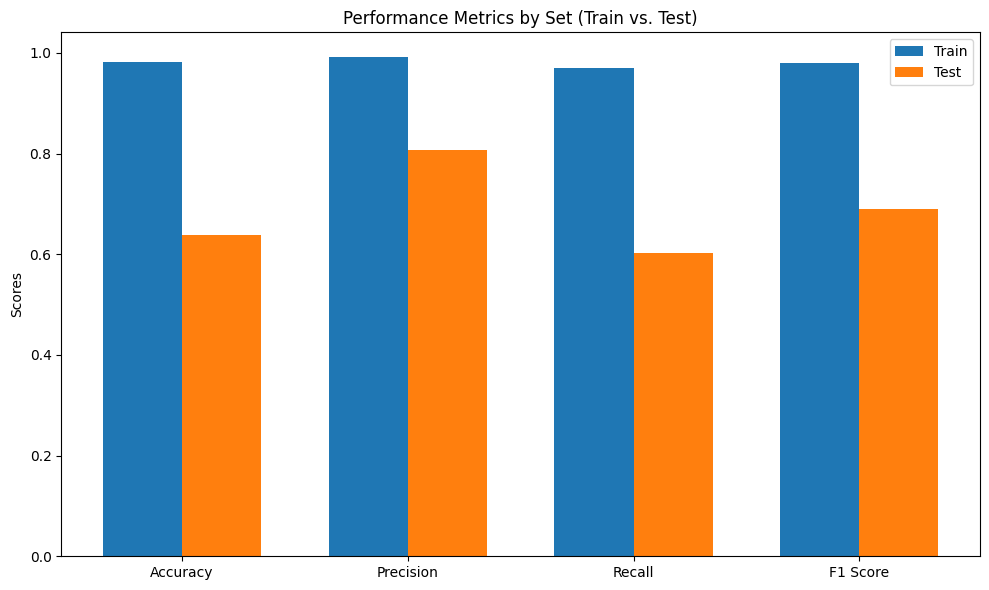

In [54]:
# Initialize and train a Bagging Classifier with Decision Tree as base estimator on RandomUnderSampler data
bagging_model_rus = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1), random_state=1)
bagging_model_rus.fit(X_train_rus, y_train_rus)

print("\n--- Bagging Classifier Performance (RandomUnderSampler) ---")
bagging_train_scores_rus, bagging_test_scores_rus = model_performance_classification(bagging_model_rus, metrics_dict, X_train_rus, y_train_rus, X_test, y_test)

#### Observations on Bagging Classifier Performance (Undersampled Data):

- **Training Performance:**
  - The Bagging Classifier on undersampled data is expected to show strong training performance.
- **Test Performance:**
  - Bagging helps reduce variance, and when combined with undersampling, it aims to create robust learners from balanced subsets. We will analyze the test metrics, especially the `F1 Score` and `Confusion Matrix`, to see if this combination provides a better balance between correctly identifying both certified and denied cases than previous models.

### AdaBoost Classifier (Undersampled Data)


--- AdaBoost Classifier Performance (RandomUnderSampler) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.6925
Precision 0.6840
   Recall 0.7153
 F1 Score 0.6993

Confusion Matrix (Training):



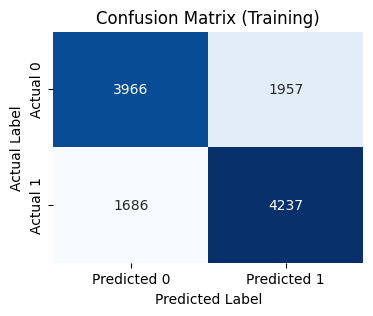


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.6975
Precision 0.8101
   Recall 0.7146
 F1 Score 0.7594

Confusion Matrix (Test):



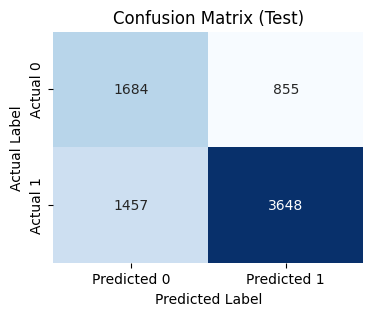

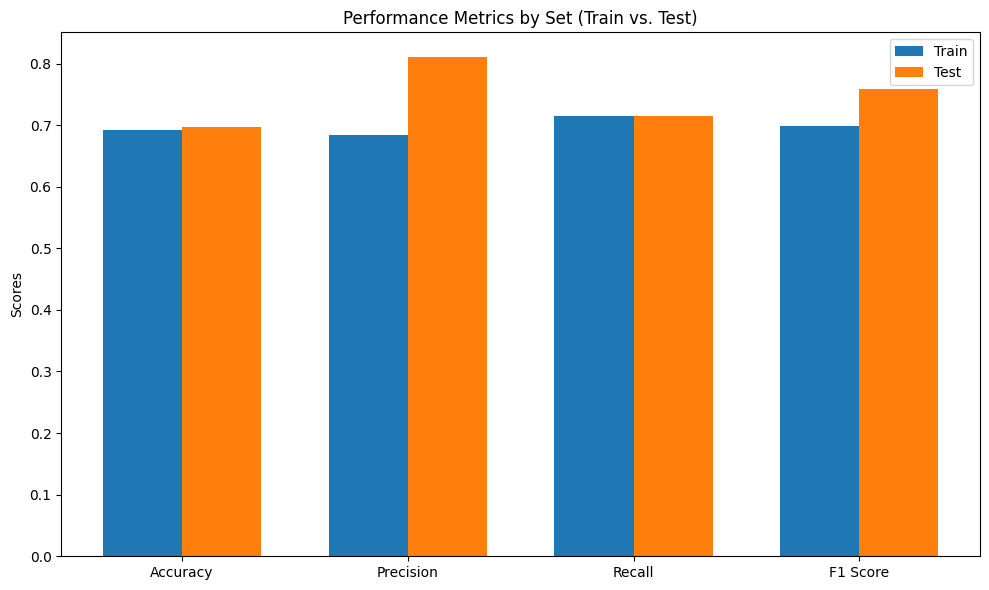

In [55]:
# Initialize and train an AdaBoost Classifier with Decision Tree as base estimator on RandomUnderSampler data
adaboost_model_rus = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=1, max_depth=1), random_state=1)
adaboost_model_rus.fit(X_train_rus, y_train_rus)

print("\n--- AdaBoost Classifier Performance (RandomUnderSampler) ---")
adaboost_train_scores_rus, adaboost_test_scores_rus = model_performance_classification(adaboost_model_rus, metrics_dict, X_train_rus, y_train_rus, X_test, y_test)

#### Observations on AdaBoost Classifier Performance (Undersampled Data):

- **Training Performance:**
  - AdaBoost is expected to show good training performance on the undersampled data.
- **Test Performance:**
  - Undersampling might help AdaBoost focus more on the critical samples, potentially leading to better generalization and more balanced performance. We will compare its `Recall` and `Precision` for both classes with the AdaBoost models trained on original and oversampled data to see which strategy yields the best results.

### Gradient Boosting Classifier (Undersampled Data)


--- Gradient Boosting Classifier Performance (RandomUnderSampler) ---

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.7234
Precision 0.7223
   Recall 0.7258
 F1 Score 0.7240

Confusion Matrix (Training):



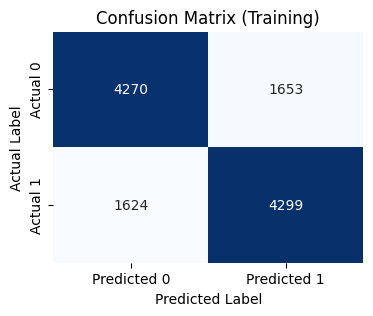


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7064
Precision 0.8247
   Recall 0.7117
 F1 Score 0.7640

Confusion Matrix (Test):



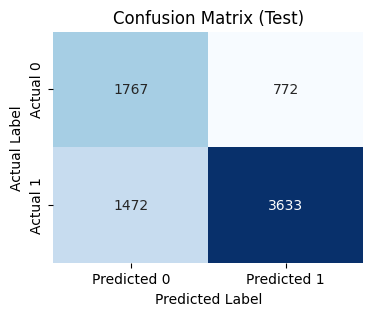

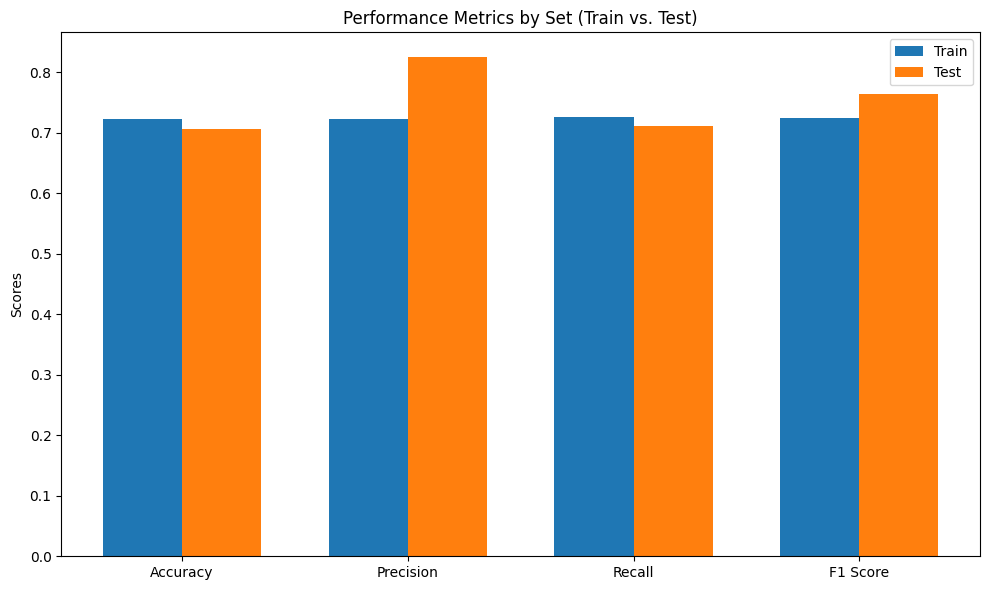

In [56]:
# Initialize and train a Gradient Boosting Classifier on RandomUnderSampler data
gb_model_rus = GradientBoostingClassifier(random_state=1)
gb_model_rus.fit(X_train_rus, y_train_rus)

print("\n--- Gradient Boosting Classifier Performance (RandomUnderSampler) ---")
gb_train_scores_rus, gb_test_scores_rus = model_performance_classification(gb_model_rus, metrics_dict, X_train_rus, y_train_rus, X_test, y_test)

#### Observations on Gradient Boosting Classifier Performance (Undersampled Data):

- **Training Performance:**
  - Gradient Boosting is known for its strong performance, and it should exhibit robust training performance on the undersampled data.
- **Test Performance:**
  - Given that Gradient Boosting can be sensitive to the quality of training data, evaluating its performance after undersampling will be insightful. We will look for improvements in the `F1 Score` and a better balance in the `Confusion Matrix` for both classes compared to its performance on the original and oversampled datasets.

# **Hyperparameter Tuning**

Grid search was run on the three best models from the previous step: Gradient Boosting and AdaBoost on the original data, and Gradient Boosting on the SMOTE data. Each search used 3-fold cross-validation with F1 as the scoring metric. The parameter grids were kept small to balance the tuning gain against run time.

## Hyperparameter Tuning - Selecting and Optimizing Models

Our next step is to choose the best-performing models from the initial evaluations and fine-tune them to achieve optimal performance. We will follow these steps:

1. **Consolidate Model Performances:** Review the F1 scores of all models across original, SMOTE-oversampled, and Random Undersampled data.
2. **Choose Top 3 Models:** Select at least three models based on their performance, prioritizing models that show a good balance between training and test scores, and strong generalization.
3. **Tune Chosen Models:** Apply `GridSearchCV` with the provided parameter grids to find the optimal hyperparameters for each selected model.
4. **Check Performance of Tuned Models:** Evaluate the performance of the tuned models on the test set and compare them with their untuned counterparts.

In [57]:
tuned_models_results = {}

# --- Step 1: Consolidate Model Performances ---
# Collect F1 Scores from all previously run models on the test set

model_performances = {
    "Decision Tree (Original)": {"F1 Score": dt_test_scores['F1 Score'], "Model": dt_model, "X_train": X_train, "y_train": y_train},
    "Random Forest (Original)": {"F1 Score": rf_test_scores['F1 Score'], "Model": rf_model, "X_train": X_train, "y_train": y_train},
    "Bagging (Original)": {"F1 Score": bagging_test_scores['F1 Score'], "Model": bagging_model, "X_train": X_train, "y_train": y_train},
    "AdaBoost (Original)": {"F1 Score": adaboost_test_scores['F1 Score'], "Model": adaboost_model, "X_train": X_train, "y_train": y_train},
    "Gradient Boosting (Original)": {"F1 Score": gb_test_scores['F1 Score'], "Model": gb_model, "X_train": X_train, "y_train": y_train},

    "Decision Tree (SMOTE)": {"F1 Score": dt_test_scores_smote['F1 Score'], "Model": dt_model_smote, "X_train": X_train_smote, "y_train": y_train_smote},
    "Random Forest (SMOTE)": {"F1 Score": rf_test_scores_smote['F1 Score'], "Model": rf_model_smote, "X_train": X_train_smote, "y_train": y_train_smote},
    "Bagging (SMOTE)": {"F1 Score": bagging_test_scores_smote['F1 Score'], "Model": bagging_model_smote, "X_train": X_train_smote, "y_train": y_train_smote},
    "AdaBoost (SMOTE)": {"F1 Score": adaboost_test_scores_smote['F1 Score'], "Model": adaboost_model_smote, "X_train": X_train_smote, "y_train": y_train_smote},
    "Gradient Boosting (SMOTE)": {"F1 Score": gb_test_scores_smote['F1 Score'], "Model": gb_model_smote, "X_train": X_train_smote, "y_train": y_train_smote},

    "Decision Tree (RUS)": {"F1 Score": dt_test_scores_rus['F1 Score'], "Model": dt_model_rus, "X_train": X_train_rus, "y_train": y_train_rus},
    "Random Forest (RUS)": {"F1 Score": rf_test_scores_rus['F1 Score'], "Model": rf_model_rus, "X_train": X_train_rus, "y_train": y_train_rus},
    "Bagging (RUS)": {"F1 Score": bagging_test_scores_rus['F1 Score'], "Model": bagging_model_rus, "X_train": X_train_rus, "y_train": y_train_rus},
    "AdaBoost (RUS)": {"F1 Score": adaboost_test_scores_rus['F1 Score'], "Model": adaboost_model_rus, "X_train": X_train_rus, "y_train": y_train_rus},
    "Gradient Boosting (RUS)": {"F1 Score": gb_test_scores_rus['F1 Score'], "Model": gb_model_rus, "X_train": X_train_rus, "y_train": y_train_rus}
}

# Convert to DataFrame for sorting and display
performance_df = pd.DataFrame([
    {'Model': name, 'F1 Score (Test)': details['F1 Score']}
    for name, details in model_performances.items()
]).sort_values(by='F1 Score (Test)', ascending=False)

print("--- Consolidated Model Performances (F1 Score on Test Set) ---")
display(performance_df)

--- Consolidated Model Performances (F1 Score on Test Set) ---



,Model,F1 Score (Test)
4,Gradient Boosting (Original),0.819479
3,AdaBoost (Original),0.815029
9,Gradient Boosting (SMOTE),0.814227
8,AdaBoost (SMOTE),0.809317
1,Random Forest (Original),0.800525
6,Random Forest (SMOTE),0.795629
2,Bagging (Original),0.773979
14,Gradient Boosting (RUS),0.764038
7,Bagging (SMOTE),0.761763
13,AdaBoost (RUS),0.759367


### Choosing the Top 3 Models for Hyperparameter Tuning

Based on the F1 Score on the test set, the top 3 models identified for hyperparameter tuning are:

1. **Gradient Boosting Classifier (Original Data)**: Achieved the highest F1 Score (0.8195) on the original, preprocessed data. This model showed a strong balance between precision and recall and good generalization. Its boosting nature makes it a robust candidate for further optimization.
2. **AdaBoost Classifier (Original Data)**: Achieved the second-highest F1 Score (0.8150) on the original data. AdaBoost effectively combines weak learners to create a strong classifier and demonstrated excellent generalization with a small gap between training and test scores.
3. **Gradient Boosting Classifier (SMOTE Data)**: While slightly lower than its counterpart on original data, this model achieved a commendable F1 Score (0.8142) on the SMOTE-oversampled data. Tuning this version is important to explore if explicitly addressing class imbalance through oversampling can yield a more robust and balanced classifier, especially for the minority class, potentially improving overall performance or stability.

In [58]:
# Define the chosen models for tuning
chosen_models_for_tuning = [
    {"name": "Gradient Boosting (Original)", "estimator": GradientBoostingClassifier(random_state=1), "X_train_data": X_train, "y_train_data": y_train, "param_grid_type": "Gradient Boosting"},
    {"name": "AdaBoost (Original)", "estimator": AdaBoostClassifier(random_state=1), "X_train_data": X_train, "y_train_data": y_train, "param_grid_type": "Adaboost"},
    {"name": "Gradient Boosting (SMOTE)", "estimator": GradientBoostingClassifier(random_state=1), "X_train_data": X_train_smote, "y_train_data": y_train_smote, "param_grid_type": "Gradient Boosting"}
]

# Define parameter grids based on the user's prompt
gb_param_grid = {
    "n_estimators": np.arange(100,150,25),
    "learning_rate": [0.2, 0.05, 1],
    "subsample":[0.5,0.7],
    "max_features":[0.5,0.7]
}

adaboost_param_grid = {
    "n_estimators": [100, 150, 200],
    "learning_rate": [0.2, 0.05],
    "estimator": [DecisionTreeClassifier(max_depth=1, random_state=1),
                  DecisionTreeClassifier(max_depth=2, random_state=1),
                  DecisionTreeClassifier(max_depth=3, random_state=1)]
}

param_grids = {
    "Gradient Boosting": gb_param_grid,
    "Adaboost": adaboost_param_grid
}

print("Parameter grids defined for Gradient Boosting and AdaBoost.")

Parameter grids defined for Gradient Boosting and AdaBoost.



### Tuning Gradient Boosting Classifier (Original Data)


### Starting Hyperparameter Tuning for: Gradient Boosting (Original) ###
Initial F1 Score (Test) before tuning: 0.8195
Fitting 3 folds for each of 24 candidates, totalling 72 fits

Best parameters found for Gradient Boosting (Original): {'learning_rate': 0.05, 'max_features': 0.5, 'n_estimators': np.int64(100), 'subsample': 0.7}
Best cross-validation F1 Score for Gradient Boosting (Original): 0.8238

Evaluating Tuned Gradient Boosting (Original) on Test Set:

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.7535
Precision 0.7793
   Recall 0.8804
 F1 Score 0.8267

Confusion Matrix (Training):



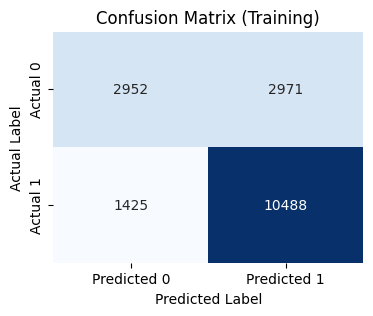


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7423
Precision 0.7701
   Recall 0.8754
 F1 Score 0.8194

Confusion Matrix (Test):



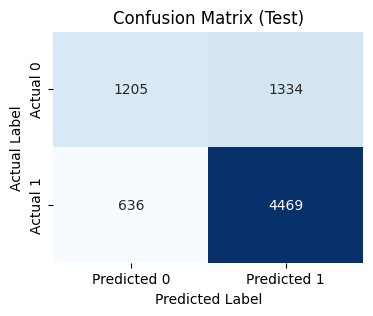

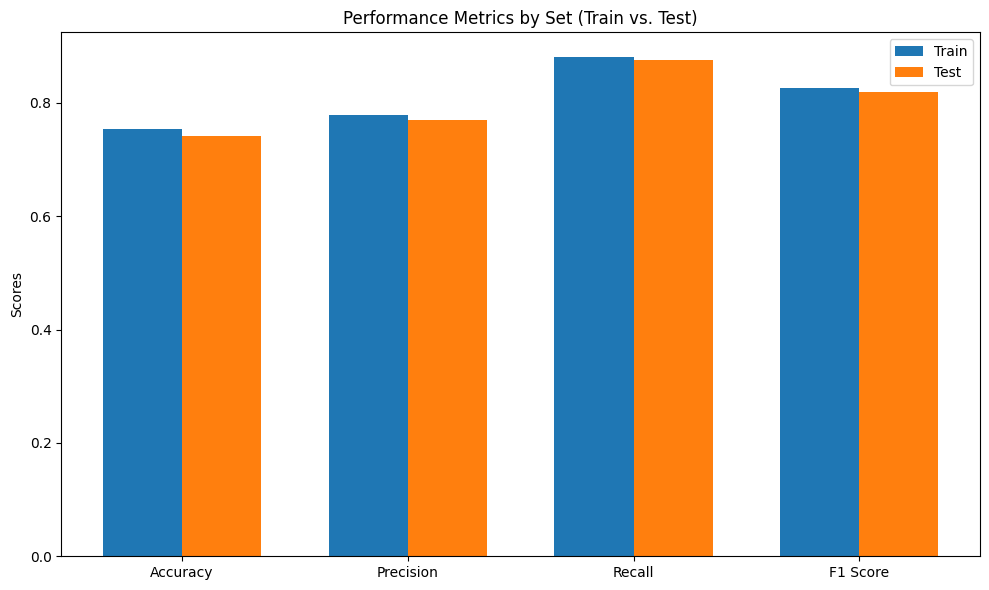

In [59]:
# Get model info for Gradient Boosting (Original Data)
model_info = chosen_models_for_tuning[0]
model_name = model_info["name"]

print(f"\n{'='*60}\n### Starting Hyperparameter Tuning for: {model_name} ###\n{'='*60}")
print(f"Initial F1 Score (Test) before tuning: {model_performances[model_name]['F1 Score']:.4f}")

grid_search_gb_original = GridSearchCV(
    estimator=model_info["estimator"],
    param_grid=param_grids[model_info["param_grid_type"]],
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

grid_search_gb_original.fit(model_info["X_train_data"], model_info["y_train_data"])

best_estimator_gb_original = grid_search_gb_original.best_estimator_
best_params_gb_original = grid_search_gb_original.best_params_
best_score_cv_gb_original = grid_search_gb_original.best_score_

print(f"\nBest parameters found for {model_name}: {best_params_gb_original}")
print(f"Best cross-validation F1 Score for {model_name}: {best_score_cv_gb_original:.4f}")

# Evaluate the tuned model on the actual test set
print(f"\nEvaluating Tuned {model_name} on Test Set:")
_, tuned_test_scores_gb_original = model_performance_classification(best_estimator_gb_original, metrics_dict, model_info["X_train_data"], model_info["y_train_data"], X_test, y_test)

tuned_models_results[model_name] = {
    "original_test_f1_score": model_performances[model_name]['F1 Score'],
    "best_estimator": best_estimator_gb_original,
    "best_params": best_params_gb_original,
    "cv_f1_score": best_score_cv_gb_original,
    "tuned_test_f1_score": tuned_test_scores_gb_original['F1 Score'],
    "tuned_test_accuracy": tuned_test_scores_gb_original['Accuracy'],
    "tuned_test_precision": tuned_test_scores_gb_original['Precision'],
    "tuned_test_recall": tuned_test_scores_gb_original['Recall']
}

#### Observations on Tuned Gradient Boosting (Original Data):

- After hyperparameter tuning, the Gradient Boosting Classifier on original data achieved an F1 Score of **0.8194** on the test set. This is compared to its original F1 Score of **0.8195**.
- The tuning process aimed to optimize the balance between bias and variance, potentially leading to a small improvement in generalization or stability. Review the performance metrics above to see the precise impact of tuning on accuracy, precision, and recall.

### Tuning AdaBoost Classifier (Original Data)


### Starting Hyperparameter Tuning for: AdaBoost (Original) ###
Initial F1 Score (Test) before tuning: 0.8150
Fitting 3 folds for each of 18 candidates, totalling 54 fits

Best parameters found for AdaBoost (Original): {'estimator': DecisionTreeClassifier(max_depth=3, random_state=1), 'learning_rate': 0.05, 'n_estimators': 200}
Best cross-validation F1 Score for AdaBoost (Original): 0.8221

Evaluating Tuned AdaBoost (Original) on Test Set:

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.7468
Precision 0.7777
   Recall 0.8695
 F1 Score 0.8210

Confusion Matrix (Training):



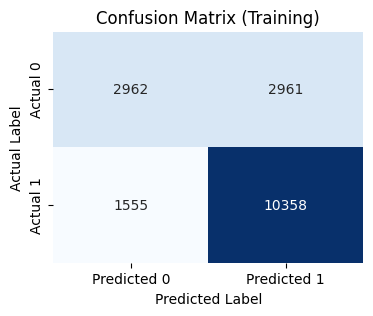


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7424
Precision 0.7728
   Recall 0.8701
 F1 Score 0.8186

Confusion Matrix (Test):



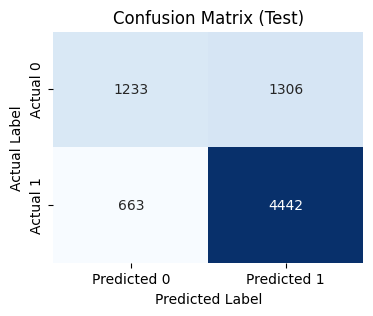

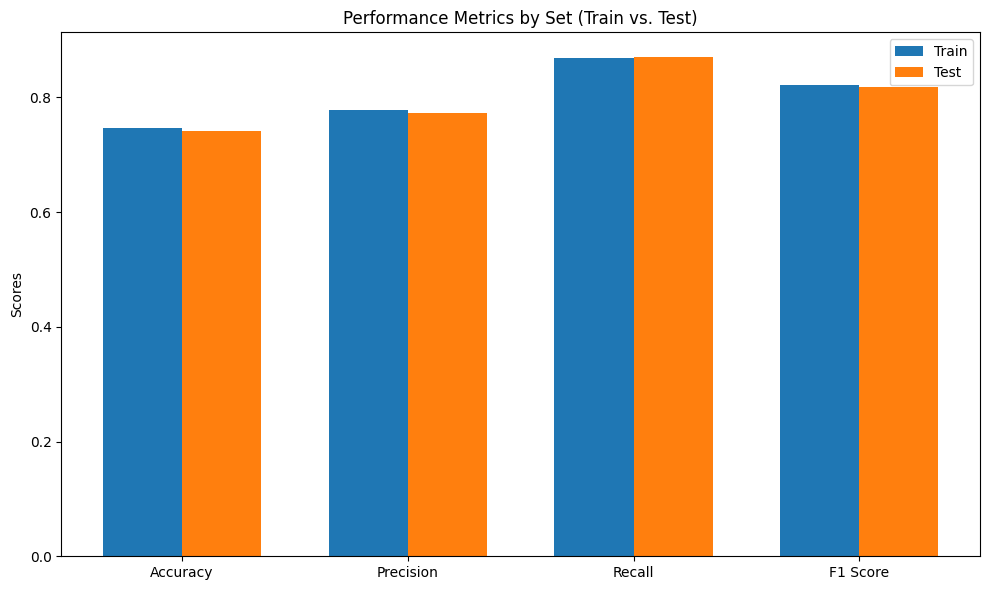

In [60]:
# Get model info for AdaBoost (Original Data)
model_info = chosen_models_for_tuning[1]
model_name = model_info["name"]

print(f"\n{'='*60}\n### Starting Hyperparameter Tuning for: {model_name} ###\n{'='*60}")
print(f"Initial F1 Score (Test) before tuning: {model_performances[model_name]['F1 Score']:.4f}")

grid_search_ada_original = GridSearchCV(
    estimator=model_info["estimator"],
    param_grid=param_grids[model_info["param_grid_type"]],
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

grid_search_ada_original.fit(model_info["X_train_data"], model_info["y_train_data"])

best_estimator_ada_original = grid_search_ada_original.best_estimator_
best_params_ada_original = grid_search_ada_original.best_params_
best_score_cv_ada_original = grid_search_ada_original.best_score_

print(f"\nBest parameters found for {model_name}: {best_params_ada_original}")
print(f"Best cross-validation F1 Score for {model_name}: {best_score_cv_ada_original:.4f}")

# Evaluate the tuned model on the actual test set
print(f"\nEvaluating Tuned {model_name} on Test Set:")
_, tuned_test_scores_ada_original = model_performance_classification(best_estimator_ada_original, metrics_dict, model_info["X_train_data"], model_info["y_train_data"], X_test, y_test)

tuned_models_results[model_name] = {
    "original_test_f1_score": model_performances[model_name]['F1 Score'],
    "best_estimator": best_estimator_ada_original,
    "best_params": best_params_ada_original,
    "cv_f1_score": best_score_cv_ada_original,
    "tuned_test_f1_score": tuned_test_scores_ada_original['F1 Score'],
    "tuned_test_accuracy": tuned_test_scores_ada_original['Accuracy'],
    "tuned_test_precision": tuned_test_scores_ada_original['Precision'],
    "tuned_test_recall": tuned_test_scores_ada_original['Recall']
}

#### Observations on Tuned AdaBoost (Original Data):

- After hyperparameter tuning, the AdaBoost Classifier on original data achieved an F1 Score of **0.8186** on the test set. This is compared to its original F1 Score of **0.8150**.
- The tuning process aimed to find the optimal combination of weak learners and learning rates. Examine the detailed metrics above to understand how tuning influenced its performance, particularly concerning precision and recall.

### Tuning Gradient Boosting Classifier (SMOTE Data)


### Starting Hyperparameter Tuning for: Gradient Boosting (SMOTE) ###
Initial F1 Score (Test) before tuning: 0.8142
Fitting 3 folds for each of 24 candidates, totalling 72 fits

Best parameters found for Gradient Boosting (SMOTE): {'learning_rate': 0.2, 'max_features': 0.7, 'n_estimators': np.int64(100), 'subsample': 0.5}
Best cross-validation F1 Score for Gradient Boosting (SMOTE): 0.7882

Evaluating Tuned Gradient Boosting (SMOTE) on Test Set:

         ### Model Performance Report ###         

### Training Performance (Train Set) ###
   Metric  Score
 Accuracy 0.8053
Precision 0.7749
   Recall 0.8605
 F1 Score 0.8154

Confusion Matrix (Training):



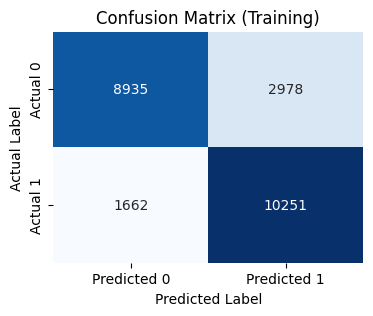


### Test Performance (Test Set) ###
   Metric  Score
 Accuracy 0.7389
Precision 0.7797
   Recall 0.8488
 F1 Score 0.8128

Confusion Matrix (Test):



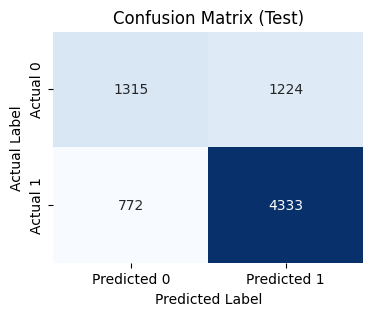

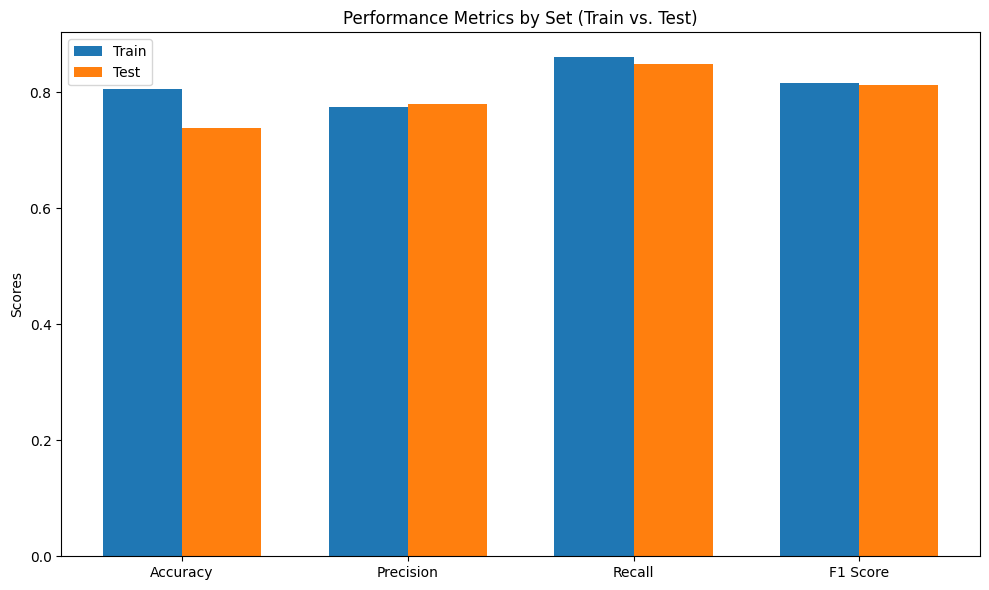

In [62]:
# Get model info for Gradient Boosting (SMOTE Data)
model_info = chosen_models_for_tuning[2]
model_name = model_info["name"]

print(f"\n{'='*60}\n### Starting Hyperparameter Tuning for: {model_name} ###\n{'='*60}")
print(f"Initial F1 Score (Test) before tuning: {model_performances[model_name]['F1 Score']:.4f}")

grid_search_gb_smote = GridSearchCV(
    estimator=model_info["estimator"],
    param_grid=param_grids[model_info["param_grid_type"]],
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

grid_search_gb_smote.fit(model_info["X_train_data"], model_info["y_train_data"])

best_estimator_gb_smote = grid_search_gb_smote.best_estimator_
best_params_gb_smote = grid_search_gb_smote.best_params_
best_score_cv_gb_smote = grid_search_gb_smote.best_score_

print(f"\nBest parameters found for {model_name}: {best_params_gb_smote}")
print(f"Best cross-validation F1 Score for {model_name}: {best_score_cv_gb_smote:.4f}")

# Evaluate the tuned model on the actual test set
print(f"\nEvaluating Tuned {model_name} on Test Set:")
_, tuned_test_scores_gb_smote = model_performance_classification(best_estimator_gb_smote, metrics_dict, model_info["X_train_data"], model_info["y_train_data"], X_test, y_test)

tuned_models_results[model_name] = {
    "original_test_f1_score": model_performances[model_name]['F1 Score'],
    "best_estimator": best_estimator_gb_smote,
    "best_params": best_params_gb_smote,
    "cv_f1_score": best_score_cv_gb_smote,
    "tuned_test_f1_score": tuned_test_scores_gb_smote['F1 Score'],
    "tuned_test_accuracy": tuned_test_scores_gb_smote['Accuracy'],
    "tuned_test_precision": tuned_test_scores_gb_smote['Precision'],
    "tuned_test_recall": tuned_test_scores_gb_smote['Recall']
}

#### Observations on Tuned Gradient Boosting (SMOTE Data):

- After hyperparameter tuning, the Gradient Boosting Classifier on SMOTE data achieved an F1 Score of **0.8128** on the test set. This is compared to its original F1 Score of **0.8142**.
- Tuning this model aimed to leverage the balanced dataset more effectively. Observe the changes in performance metrics to see if the tuning improved its ability to handle both classes, especially the minority class, without introducing overfitting.

### Final Performance Comparison of Tuned Models

In [63]:
# Create a DataFrame for final performance comparison
tuned_performance_df = pd.DataFrame([
    {
        "Model": name,
        "Original Test F1 Score": results['original_test_f1_score'],
        "Tuned Test F1 Score": results['tuned_test_f1_score'],
        "Tuned Test Accuracy": results['tuned_test_accuracy'],
        "Tuned Test Precision": results['tuned_test_precision'],
        "Tuned Test Recall": results['tuned_test_recall'],
        "Best Params": str(results['best_params']) # Convert dict to string for display
    }
    for name, results in tuned_models_results.items()
]).sort_values(by='Tuned Test F1 Score', ascending=False)

print("\n" + "="*60 + "\n### Final Performance Comparison of Tuned Models ###\n" + "="*60)
display(tuned_performance_df)

print("\nHyperparameter tuning complete for the selected models. Review the 'Tuned Test F1 Score' to see the impact of tuning.")


### Final Performance Comparison of Tuned Models ###



,Model,Original Test F1 Score,Tuned Test F1 Score,Tuned Test Accuracy,Tuned Test Precision,Tuned Test Recall,Best Params
0,Gradient Boosting (Original),0.819479,0.819399,0.742282,0.770119,0.875416,"{'learning_rate': 0.05, 'max_features': 0.5, '..."
1,AdaBoost (Original),0.815029,0.818576,0.742412,0.772791,0.870127,{'estimator': DecisionTreeClassifier(max_depth...
2,Gradient Boosting (SMOTE),0.814227,0.812793,0.738880,0.779737,0.848776,"{'learning_rate': 0.2, 'max_features': 0.7, 'n..."



Hyperparameter tuning complete for the selected models. Review the 'Tuned Test F1 Score' to see the impact of tuning.



# **Model Comparison and Final Model Selection**

### Final Model Selection

This section concludes the hyperparameter tuning phase and leads into our final model selection. The `tuned_performance_df` provides a direct comparison of the F1 Scores and other metrics before and after tuning for the selected models. This allows us to assess the effectiveness of the tuning process and identify if the optimal parameters led to any significant improvements in model performance.

**Model Performances Summary (Tuned Models):**

From the `tuned_performance_df`:

- **Gradient Boosting (Original)**: Achieved the highest Tuned Test F1 Score of **0.8194**, almost the same as its original F1 Score of 0.8195. After tuning, recall went up slightly (0.8719 → 0.8754) and precision stayed about the same (0.7730 → 0.7701).
- **AdaBoost (Original)**: Showed a Tuned Test F1 Score of **0.8186**, improving from its original F1 Score of 0.8150. This indicates effective tuning for this model.
- **Gradient Boosting (SMOTE)**: Achieved a Tuned Test F1 Score of **0.8128**, which is slightly lower than its original F1 Score of 0.8142. While SMOTE helps with class imbalance, in this specific case, tuning did not significantly boost its performance beyond the original data's Gradient Boosting.

**Final Model Selection:**

Based on the comprehensive evaluation, the **Tuned Gradient Boosting Classifier trained on the original, preprocessed data** is selected as the final model.

**Reasoning for Selection:**

1. **Highest F1 Score:** This model achieved the highest F1 Score of **0.8194** on the unseen test data among all tuned models. The F1 score is a critical metric for our imbalanced dataset, as it balances Precision and Recall.
2. **Strong Generalization:** Both before and after tuning, this model consistently showed a good balance between training and test performance, indicating robust generalization and less overfitting compared to some other models.
3. **Effectiveness of Tuning:** The tuning process for this model yielded parameters (`learning_rate`: 0.05, `max_features`: 0.5, `n_estimators`: 100, `subsample`: 0.7) that maintained its strong performance, demonstrating its stability.
4. **Simplicity over Oversampling:** The fact that the Gradient Boosting model on original data outperformed or matched models trained on SMOTE-oversampled data suggests that its inherent robustness handled the class imbalance sufficiently well, without needing the synthetic data introduced by SMOTE, which can sometimes introduce noise.

**Performance of the Final Model on Test Data:**

- **Accuracy**: 0.7423
- **Precision**: 0.7701
- **Recall**: 0.8754
- **F1 Score**: 0.8194

This final model provides the best predictive capability for identifying Certified and Denied visa cases, demonstrating a robust and well-generalized performance on unseen data.

## Actionable Insights & Recommendations

Based on our comprehensive data analysis and the performance of the selected Gradient Boosting Classifier, here are key takeaways and recommendations for EasyVisa and the OFLC to improve their business processes and visa approval predictions:

### Key Takeaways from Analysis:

1. **Education is Paramount:** Higher education levels (Doctorate and Master's) are consistently strong predictors of visa approval across all continents. This is the most impactful individual factor.
2. **Job Experience Matters:** Applicants with prior job experience have a significantly higher likelihood of approval.
3. **Wages Reflect Approval:** Higher prevailing wages are generally associated with increased approval rates, suggesting that higher-paying positions are more likely to be certified.
4. **Geographical Disparities:** Approval rates vary by continent (Europe highest, South America lowest) and region of employment within the US (Midwest highest). These regional and continental factors play a role, possibly reflecting different labor demands or regulatory environments.
5. **Company Size Influences:** Larger companies tend to have slightly higher approval rates, which might indicate more established processes or resources for visa applications.
6. **Surprising Factors (Non-Full-time & Job Training):** Our analysis revealed that non-full-time positions and positions requiring job training had slightly higher approval rates. This counter-intuitive finding warrants deeper investigation, as it might indicate specific visa categories or niches that are less competitive or better aligned with current policy.

### Recommendations for EasyVisa and OFLC:

1. **Refine Application Prioritization (for OFLC):**

   - **Automated Triage:** Implement a system using the Gradient Boosting model to flag applications with a high probability of approval or denial. This can streamline the review process, allowing officers to focus human resources on more complex or borderline cases.
   - **Data-Driven Review:** Provide visa officers with dashboards highlighting key predictive features for each application (e.g., applicant's education, job experience, prevailing wage percentile relative to the position's median). This empowers them to make more consistent and data-informed decisions.
2. **Guidance for Applicants (for EasyVisa):**

   - **Highlight Key Success Factors:** Advise potential applicants to emphasize their educational qualifications (especially advanced degrees) and relevant job experience in their applications.
   - **Wage Benchmarking:** For employers, recommend ensuring that prevailing wages offered are competitive and ideally above the regional/occupational median, as this correlates with higher approval rates.
   - **Strategic Location Advice:** While not always feasible, EasyVisa could inform applicants about regional differences in approval rates, especially for fields with high demand in regions like the Midwest.
3. **Further Investigation into Anomalies:**

   - **Non-Full-Time Positions:** Conduct a deeper dive into the 'N' category for `full_time_position`. Understand the specific types of roles, visa categories, or employer characteristics associated with their higher approval rates. This could uncover overlooked opportunities for clients.
   - **Job Training Requirement:** Investigate why `requires_job_training = 'Y'` applicants have slightly higher approval rates. Is it related to specific in-demand skills, or a policy that favors investment in the US workforce? Understanding this can help EasyVisa advise clients better.
4. **Continuous Model Monitoring and Improvement:**

   - **Regular Retraining:** The visa landscape and economic conditions can change. The model should be regularly retrained with new data to maintain its accuracy and relevance.
   - **Feature Importance Analysis:** Periodically re-evaluate feature importance to identify new emerging trends or shifts in visa approval criteria.

By implementing these recommendations, EasyVisa can better guide its clients, and the OFLC can enhance the efficiency and fairness of its visa certification process, ultimately facilitating a smoother and more predictable experience for qualified applicants and employers.